In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# Locate project folders
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

CLEANED_DIR = PROJECT_DIR / "data" / "cleaned"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Cleaned data folder:", CLEANED_DIR)
print("Folder exists:", CLEANED_DIR.exists())

cleaned_files = sorted(
    CLEANED_DIR.glob("CLEAN_House*.csv")
)

print("Number of cleaned household files:", len(cleaned_files))
print([f.name for f in cleaned_files])


Project: c:\Users\jtush\OneDrive\Desktop\Flock_Energy
Cleaned data folder: c:\Users\jtush\OneDrive\Desktop\Flock_Energy\data\cleaned
Folder exists: True
Number of cleaned household files: 20
['CLEAN_House1.csv', 'CLEAN_House10.csv', 'CLEAN_House11.csv', 'CLEAN_House12.csv', 'CLEAN_House13.csv', 'CLEAN_House15.csv', 'CLEAN_House16.csv', 'CLEAN_House17.csv', 'CLEAN_House18.csv', 'CLEAN_House19.csv', 'CLEAN_House2.csv', 'CLEAN_House20.csv', 'CLEAN_House21.csv', 'CLEAN_House3.csv', 'CLEAN_House4.csv', 'CLEAN_House5.csv', 'CLEAN_House6.csv', 'CLEAN_House7.csv', 'CLEAN_House8.csv', 'CLEAN_House9.csv']


In [3]:

# Official REFIT washing-machine channel mapping
# House 4 has two washing machines; analyse each separately.
WASHING_MACHINE_CHANNELS = {
    1: ["Appliance5"],
    2: ["Appliance2"],
    3: ["Appliance6"],
    4: ["Appliance4", "Appliance5"],
    5: ["Appliance3"],
    6: ["Appliance2"],
    7: ["Appliance5"],
    8: ["Appliance4"],
    9: ["Appliance3"],
    10: ["Appliance5"],
    11: ["Appliance3"],
    13: ["Appliance3"],
    15: ["Appliance3"],
    16: ["Appliance5"],
    17: ["Appliance4"],
    18: ["Appliance5"],
    19: ["Appliance2"],
    20: ["Appliance4"],
    21: ["Appliance3"],
}

# Inspect columns and a few rows
for f in cleaned_files[:4]:
    sample = pd.read_csv(f, nrows=3)
    print(f"\n{f.name}")
    print("Columns:", sample.columns.tolist())
    print(sample.head(2).to_string(index=False))



CLEAN_House1.csv
Columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
               Time       Unix  Aggregate  Appliance1  Appliance2  Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  Appliance9  Issues
2013-10-09 13:06:17 1381323977        523          74           0          69           0           0           0           0           0           1       0
2013-10-09 13:06:31 1381323991        526          75           0          69           0           0           0           0           0           1       0

CLEAN_House10.csv
Columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
               Time       Unix  Aggregate  Appliance1  Appliance2  Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  

In [5]:

import pandas as pd
import numpy as np
from pathlib import Path
import re

# Select six households
SELECTED_HOUSES = [1, 2, 3, 5, 6, 9]

# Official REFIT washing-machine channel mapping
WASHING_MACHINE_CHANNELS = {
    1: "Appliance5",
    2: "Appliance2",
    3: "Appliance6",
    5: "Appliance3",
    6: "Appliance2",
    9: "Appliance3",
}

household_data = {}
quality_rows = []

for house in SELECTED_HOUSES:
    file = CLEANED_DIR / f"CLEAN_House{house}.csv"

    if not file.exists():
        print(f"Missing file: {file.name}")
        continue

    df = pd.read_csv(file)

    # Your files use Time, not DATETIME
    df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
    df = df.dropna(subset=["Time"]).sort_values("Time")

    # Remove duplicate timestamps using the documented rule:
    # retain the last record at each timestamp.
    df = df.drop_duplicates(subset=["Time"], keep="last")
    df = df.set_index("Time")

    wm = WASHING_MACHINE_CHANNELS[house]

    required = [wm, "Aggregate"]
    missing_cols = [c for c in required if c not in df.columns]

    if missing_cols:
        print(f"House {house}: missing columns {missing_cols}")
        continue

    df[required] = df[required].apply(
        pd.to_numeric, errors="coerce"
    )

    # Resample power readings to 1-minute means.
    # Missing minutes remain NaN.
    one_min = df[required].resample("1min").mean()

    household_data[house] = {
        "raw": df,
        "one_min": one_min,
        "channel": wm,
    }

    s = one_min[wm]
    observed = s.notna()

    quality_rows.append({
        "House": house,
        "WM_channel": wm,
        "Start": one_min.index.min(),
        "End": one_min.index.max(),
        "Total_minutes": len(one_min),
        "Observed_minutes": int(observed.sum()),
        "Missing_minutes": int(s.isna().sum()),
        "Missing_pct": round(s.isna().mean() * 100, 2),
        "Zero_minutes": int((s[observed] == 0).sum()),
        "Zero_pct_observed": round(
            (s[observed] == 0).mean() * 100, 2
        ) if observed.any() else np.nan,
    })

quality_df = pd.DataFrame(quality_rows)

print("Households loaded:", list(household_data.keys()))
display(quality_df)


Households loaded: [1, 2, 3, 5, 6, 9]


,House,WM_channel,Start,End,Total_minutes,Observed_minutes,Missing_minutes,Missing_pct,Zero_minutes,Zero_pct_observed
0,1,Appliance5,2013-10-09 13:06:00,2015-07-10 11:56:00,920091,803773,116318,12.64,784122,97.56
1,2,Appliance2,2013-09-17 22:08:00,2015-05-28 08:05:00,889078,670164,218914,24.62,632568,94.39
2,3,Appliance6,2013-09-25 19:21:00,2015-06-02 10:55:00,885095,784402,100693,11.38,730356,93.11
3,5,Appliance3,2013-09-26 09:56:00,2015-07-06 17:48:00,933593,846373,87220,9.34,441149,52.12
4,6,Appliance2,2013-11-28 12:15:00,2015-06-28 22:14:00,831480,704709,126771,15.25,686610,97.43
5,9,Appliance3,2013-12-17 17:26:00,2015-07-08 18:52:00,818007,692184,125823,15.38,627366,90.64


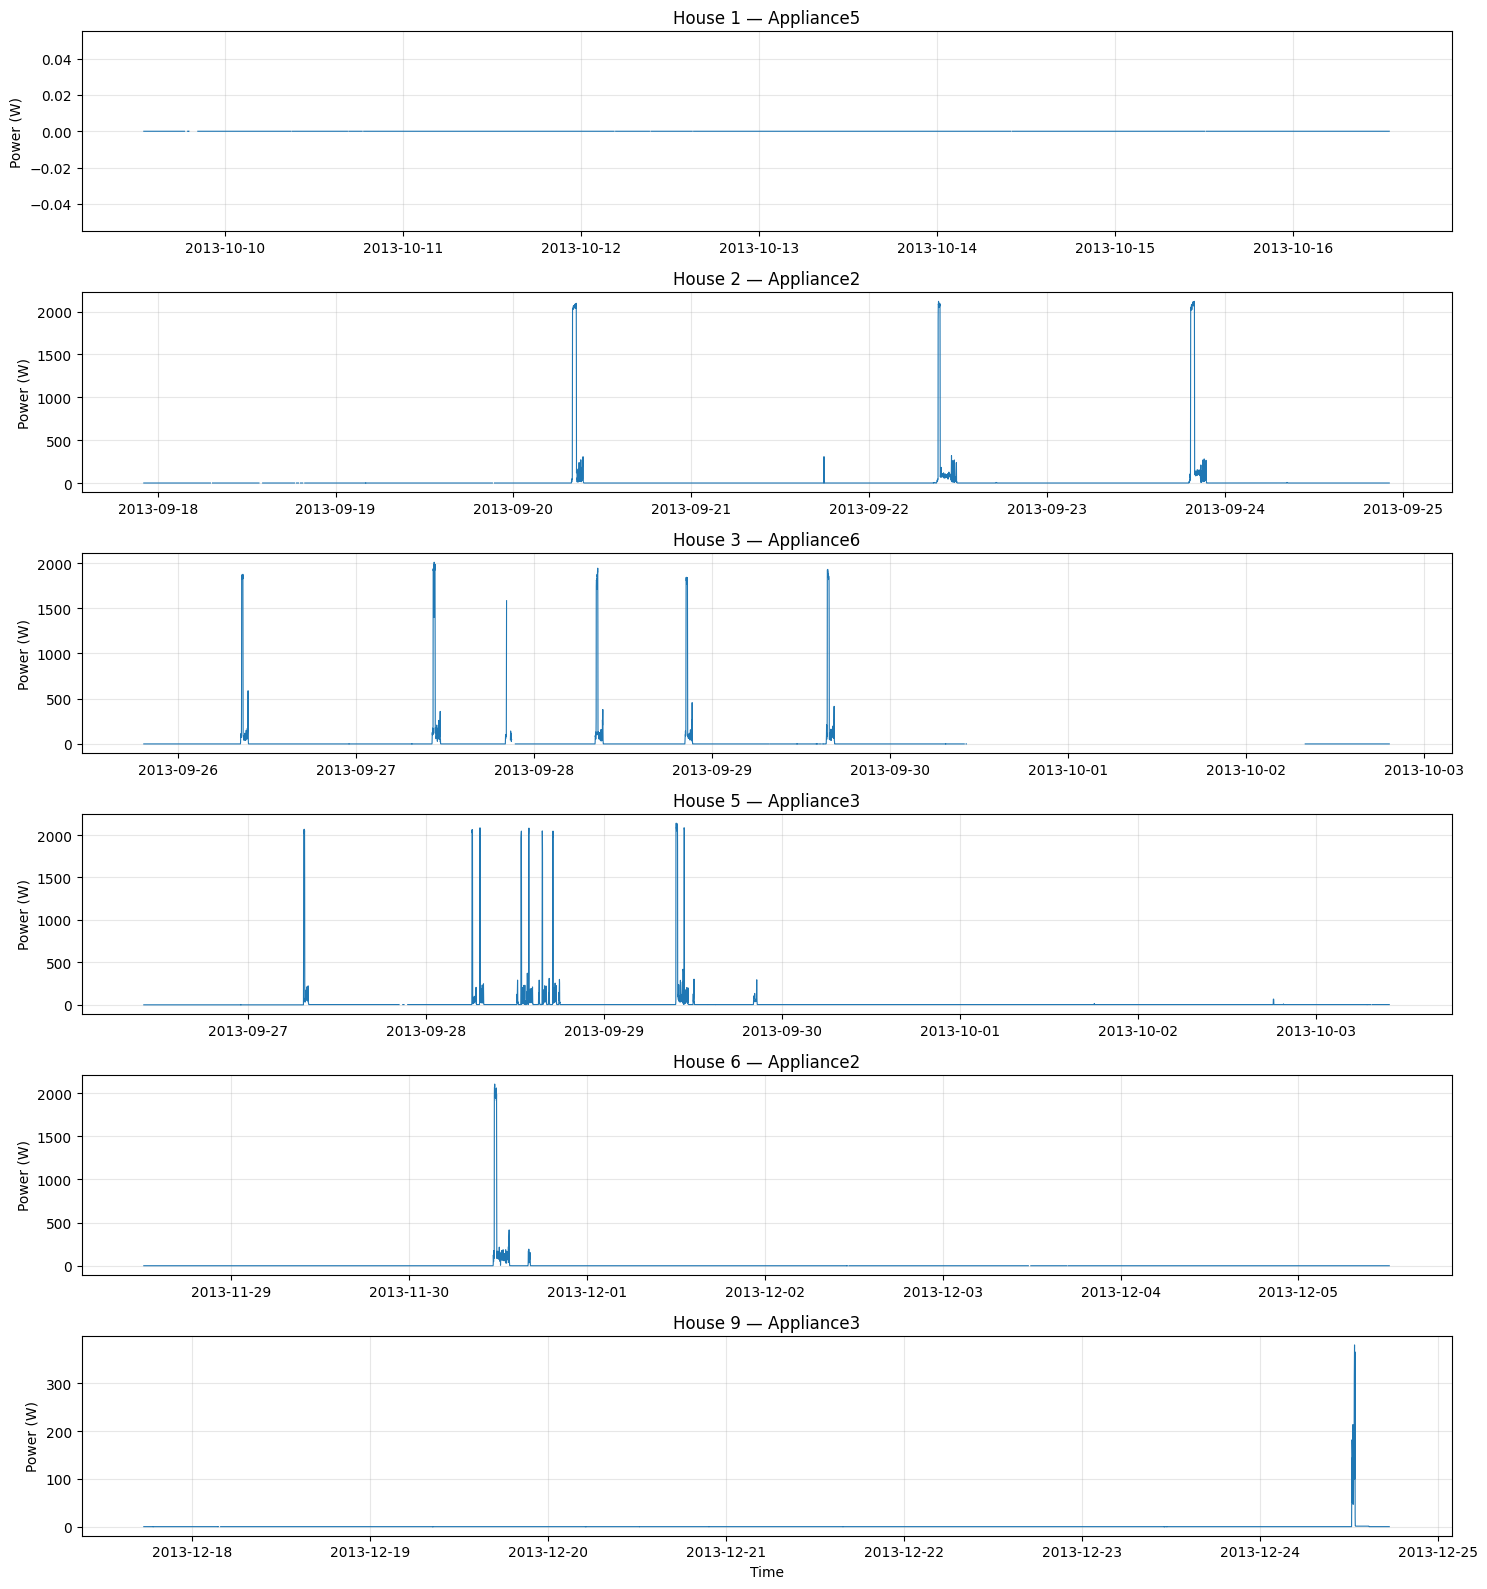

In [6]:

fig, axes = plt.subplots(6, 1, figsize=(15, 16), sharex=False)

for ax, house in zip(axes, SELECTED_HOUSES):
    if house not in household_data:
        ax.set_title(f"House {house}: data unavailable")
        continue

    data = household_data[house]["one_min"]
    wm = household_data[house]["channel"]

    # Plot a representative window of up to 7 days
    start = data.index.min()
    end = start + pd.Timedelta(days=7)
    sample = data.loc[start:end]

    ax.plot(sample.index, sample[wm], linewidth=0.8)
    ax.set_title(f"House {house} — {wm}")
    ax.set_ylabel("Power (W)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()


In [7]:

summary_rows = []

for house, info in household_data.items():
    df = info["one_min"]
    channel = info["channel"]
    s = df[channel].dropna()

    summary_rows.append({
        "House": house,
        "Channel": channel,
        "Observed_minutes": len(s),
        "Positive_minutes": int((s > 0).sum()),
        "Above_10W_minutes": int((s >= 10).sum()),
        "Above_100W_minutes": int((s >= 100).sum()),
        "Peak_power_W": s.max(),
        "Median_positive_power_W": (
            s[s > 0].median() if (s > 0).any() else np.nan
        ),
        "Distinct_positive_days": (
            int(s[s > 0].groupby(s[s > 0].index.date).size().size)
            if (s > 0).any() else 0
        )
    })

activity_summary = pd.DataFrame(summary_rows)
display(activity_summary)


,House,Channel,Observed_minutes,Positive_minutes,Above_10W_minutes,Above_100W_minutes,Peak_power_W,Median_positive_power_W,Distinct_positive_days
0,1,Appliance5,803773,19651,16219,9811,2461.750000,99.750000,323
1,2,Appliance2,670164,37596,33568,12564,2250.555556,73.750000,305
2,3,Appliance6,784402,54046,45196,27009,2592.000000,99.888889,394
3,5,Appliance3,846373,405224,71290,36406,2344.142857,3.000000,524
4,6,Appliance2,704709,18099,13405,7364,2185.000000,85.083333,240
5,9,Appliance3,692184,64818,18731,12043,2371.500000,1.000000,215


In [8]:

house = 1
df1 = household_data[house]["one_min"]
wm1 = household_data[house]["channel"]
s1 = df1[wm1]

print("House 1 channel:", wm1)
print("Minimum:", s1.min())
print("Maximum:", s1.max())
print("Positive minutes:", int((s1 > 0).sum()))
print("Minutes >= 10 W:", int((s1 >= 10).sum()))

# Show the 20 largest readings
print("\nLargest readings:")
display(s1.nlargest(20))


House 1 channel: Appliance5
Minimum: 0.0
Maximum: 2461.75
Positive minutes: 19651
Minutes >= 10 W: 16219

Largest readings:


Time
2014-09-08 13:02:00    2461.750000
2014-07-03 13:05:00    2458.750000
2014-09-03 10:14:00    2453.428571
2014-07-02 12:22:00    2446.571429
2014-01-07 11:56:00    2446.000000
2014-01-07 11:57:00    2446.000000
2014-01-07 11:58:00    2446.000000
2014-01-07 11:59:00    2446.000000
2013-12-17 10:27:00    2440.500000
2015-04-15 13:26:00    2428.333333
2014-08-20 09:25:00    2425.200000
2014-06-19 13:58:00    2422.100000
2014-09-08 12:24:00    2420.500000
2014-04-11 09:13:00    2419.800000
2014-08-23 10:04:00    2419.500000
2013-12-16 14:00:00    2419.100000
2015-02-25 12:34:00    2417.625000
2014-05-21 12:21:00    2417.200000
2014-09-08 13:03:00    2415.250000
2014-07-02 12:21:00    2409.714286
Name: Appliance5, dtype: float64

In [9]:

# Screen every mapped household, not just the initial six

candidate_rows = []

for file in cleaned_files:
    match = re.search(r"House(\d+)", file.name)
    if not match:
        continue

    house = int(match.group(1))

    if house not in WASHING_MACHINE_CHANNELS:
        continue

    df = pd.read_csv(file)

    if "Time" not in df.columns:
        continue

    df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
    df = df.dropna(subset=["Time"]).sort_values("Time")
    df = df.drop_duplicates("Time", keep="last")
    df = df.set_index("Time")

    channel = WASHING_MACHINE_CHANNELS[house]

    if channel not in df.columns:
        continue

    s = pd.to_numeric(df[channel], errors="coerce")
    s = s.resample("1min").mean()

    valid = s.dropna()
    active = valid[valid >= 10]

    # Count separate active episodes with a simple preliminary rule.
    # This is for screening only, not the final cycle detector.
    active_mask = s >= 10
    group_id = (active_mask != active_mask.shift()).cumsum()
    runs = active_mask[active_mask].groupby(
        group_id[active_mask]
    ).size()

    candidate_rows.append({
        "House": house,
        "Channel": channel,
        "Start": s.index.min(),
        "End": s.index.max(),
        "Observed_pct": round(s.notna().mean() * 100, 2),
        "Missing_pct": round(s.isna().mean() * 100, 2),
        "Positive_minutes": int((valid > 0).sum()),
        "Minutes_ge_10W": int((valid >= 10).sum()),
        "Median_positive_W": (
            round(valid[valid > 0].median(), 2)
            if (valid > 0).any() else np.nan
        ),
        "Peak_W": round(valid.max(), 2) if len(valid) else np.nan,
        "Active_runs_ge_5min": int((runs >= 5).sum()),
    })

candidate_df = pd.DataFrame(candidate_rows)

candidate_df = candidate_df.sort_values(
    ["Observed_pct", "Active_runs_ge_5min"],
    ascending=False
).reset_index(drop=True)

display(candidate_df)


,House,Channel,Start,End,Observed_pct,Missing_pct,Positive_minutes,Minutes_ge_10W,Median_positive_W,Peak_W,Active_runs_ge_5min
0,5,Appliance3,2013-09-26 09:56:00,2015-07-06 17:48:00,90.66,9.34,405224,71290,3.00,2344.14,1561
1,3,Appliance6,2013-09-25 19:21:00,2015-06-02 10:55:00,88.62,11.38,54046,45196,99.89,2592.00,833
2,1,Appliance5,2013-10-09 13:06:00,2015-07-10 11:56:00,87.36,12.64,19651,16219,99.75,2461.75,907
3,6,Appliance2,2013-11-28 12:15:00,2015-06-28 22:14:00,84.75,15.25,18099,13405,85.08,2185.00,212
4,9,Appliance3,2013-12-17 17:26:00,2015-07-08 18:52:00,84.62,15.38,64818,18731,1.00,2371.50,286
5,2,Appliance2,2013-09-17 22:08:00,2015-05-28 08:05:00,75.38,24.62,37596,33568,73.75,2250.56,784


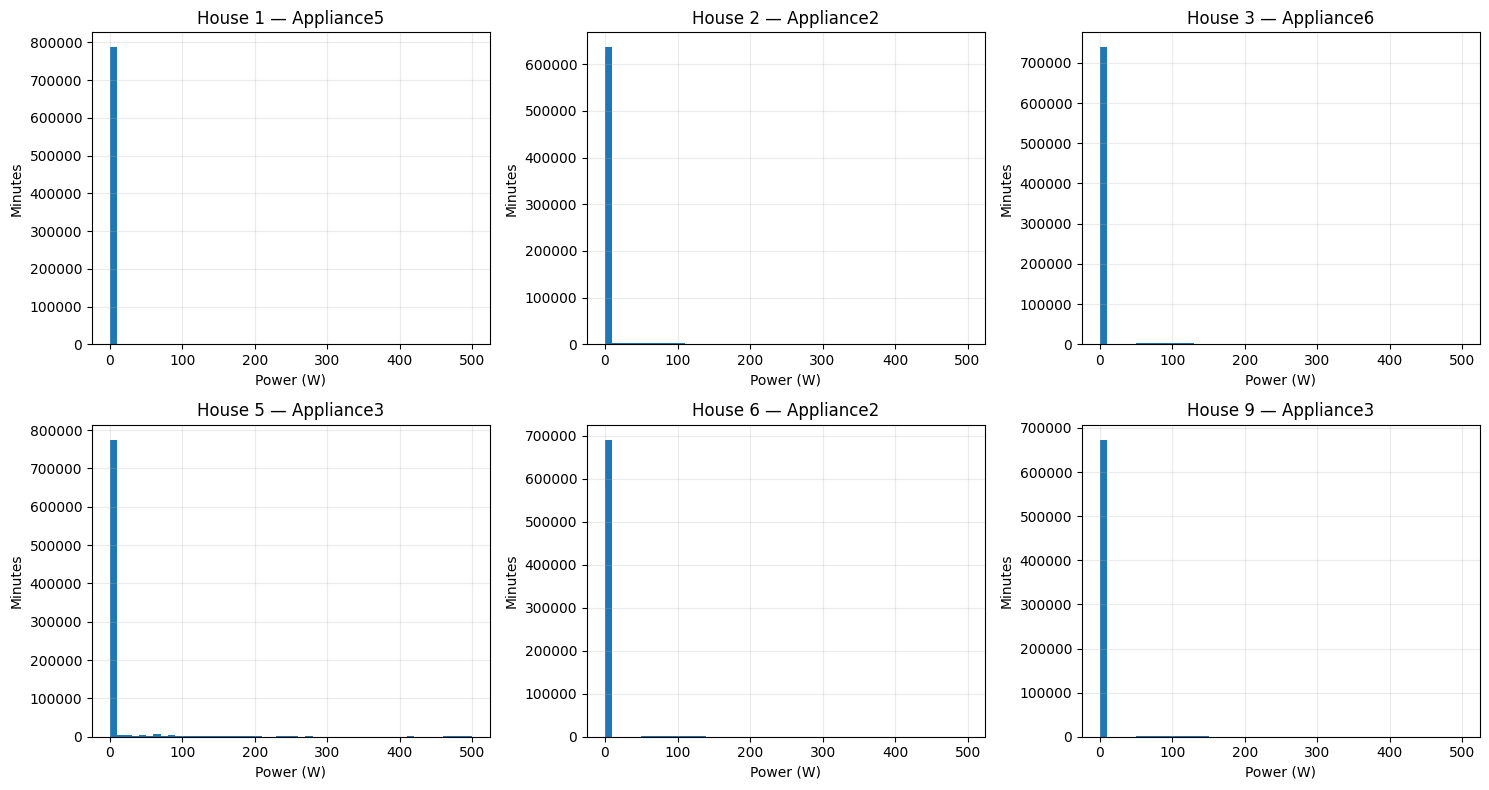

In [10]:

# Compare power distributions for the six candidate households

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, house in zip(axes, SELECTED_HOUSES):
    if house not in household_data:
        continue

    info = household_data[house]
    s = info["one_min"][info["channel"]].dropna()

    # Limit the histogram range so extreme peaks don't hide the distribution
    ax.hist(s[s <= 500], bins=50)
    ax.set_title(f"House {house} — {info['channel']}")
    ax.set_xlabel("Power (W)")
    ax.set_ylabel("Minutes")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [11]:

thresholds = [10, 50, 100, 200, 400]

threshold_rows = []

for house in SELECTED_HOUSES:
    if house not in household_data:
        continue

    info = household_data[house]
    s = info["one_min"][info["channel"]].dropna()

    row = {"House": house, "Channel": info["channel"]}

    for threshold in thresholds:
        row[f">={threshold}W_minutes"] = int((s >= threshold).sum())

    threshold_rows.append(row)

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)


,House,Channel,>=10W_minutes,>=50W_minutes,>=100W_minutes,>=200W_minutes,>=400W_minutes
0,1,Appliance5,16219,13950,9811,5658,4381
1,2,Appliance2,33568,23963,12564,6951,5001
2,3,Appliance6,45196,40735,27009,14012,11236
3,5,Appliance3,71290,56117,36406,22308,15099
4,6,Appliance2,13405,12188,7364,2940,2083
5,9,Appliance3,18731,17578,12043,6076,4229


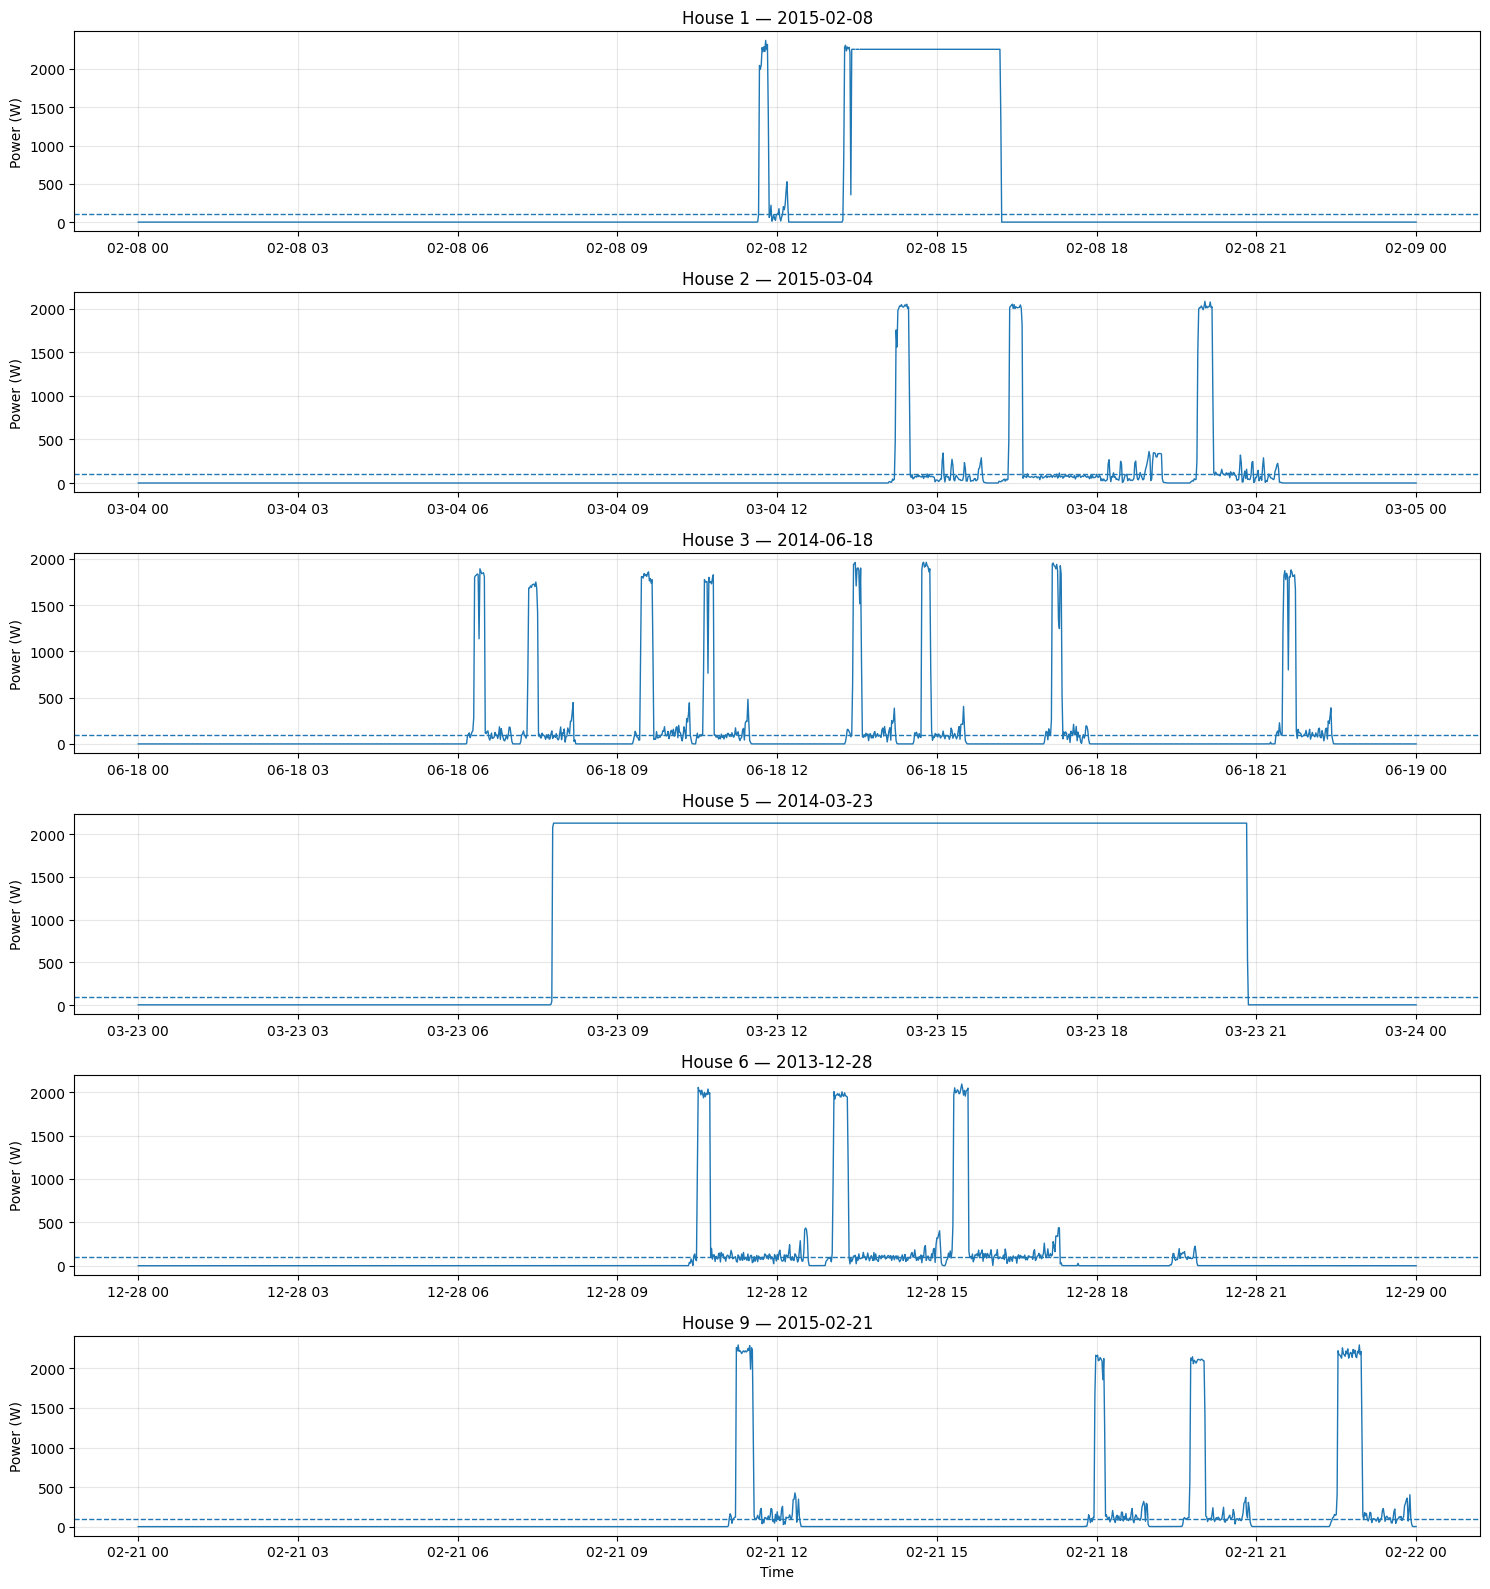

In [12]:

fig, axes = plt.subplots(6, 1, figsize=(15, 16))

for ax, house in zip(axes, SELECTED_HOUSES):
    if house not in household_data:
        continue

    info = household_data[house]
    df = info["one_min"]
    channel = info["channel"]

    # Select the day with the largest number of readings >= 100 W
    active = df[channel] >= 100

    if not active.any():
        ax.set_title(f"House {house}: no readings >= 100 W")
        continue

    active_dates = pd.Series(
        active[active].index.normalize()
    ).value_counts()

    chosen_day = pd.Timestamp(active_dates.index[0])
    day_data = df.loc[
        chosen_day:chosen_day + pd.Timedelta(days=1),
        channel
    ]

    ax.plot(day_data.index, day_data.values, linewidth=1)
    ax.axhline(100, linestyle="--", linewidth=1)
    ax.set_title(f"House {house} — {chosen_day.date()}")
    ax.set_ylabel("Power (W)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()


In [13]:

# Preliminary cycle detection: 100 W, minimum 5 minutes, merge gaps <= 2 minutes

POWER_THRESHOLD = 100
MIN_DURATION_MIN = 5
MERGE_GAP_MIN = 2

cycle_tables = {}

def detect_cycles(series, threshold=100, min_duration=5, merge_gap=2):
    s = series.sort_index()
    observed = s.notna()
    active = observed & (s >= threshold)

    # Find consecutive active runs
    groups = (active != active.shift(fill_value=False)).cumsum()
    runs = []

    for _, segment in active.groupby(groups):
        if not segment.iloc[0]:
            continue

        start = segment.index[0]
        end = segment.index[-1]
        runs.append([start, end])

    # Merge nearby runs only if every intervening minute is observed
    merged = []

    for start, end in runs:
        if merged:
            prev_start, prev_end = merged[-1]
            gap_start = prev_end + pd.Timedelta(minutes=1)
            gap_end = start - pd.Timedelta(minutes=1)

            gap = s.loc[gap_start:gap_end]
            gap_length = len(gap)

            if (
                0 < gap_length <= merge_gap
                and gap.notna().all()
            ):
                merged[-1][1] = end
                continue

        merged.append([start, end])

    rows = []

    for start, end in merged:
        # Include the complete minute-by-minute interval
        event = s.loc[start:end]
        duration = len(event)

        if duration < min_duration:
            continue

        rows.append({
            "Start": start,
            "End": end,
            "Duration_min": duration,
            "Peak_power_W": event.max(),
            "Mean_power_W": event.mean(),
            "Energy_Wh": event.sum() / 60,
        })

    return pd.DataFrame(rows)


for house in SELECTED_HOUSES:
    if house not in household_data:
        continue

    info = household_data[house]
    series = info["one_min"][info["channel"]]

    cycles = detect_cycles(
        series,
        threshold=POWER_THRESHOLD,
        min_duration=MIN_DURATION_MIN,
        merge_gap=MERGE_GAP_MIN,
    )

    cycle_tables[house] = cycles
    print(f"House {house}: {len(cycles)} detected events")

    display(cycles.head(10))


House 1: 899 detected events


,Start,End,Duration_min,Peak_power_W,Mean_power_W,Energy_Wh
0,2013-10-23 06:00:00,2013-10-23 06:09:00,10,2325.700000,1275.422222,212.570370
1,2013-10-23 06:13:00,2013-10-23 06:32:00,20,349.300000,121.320657,40.440219
2,2013-10-23 06:40:00,2013-10-23 06:49:00,10,2368.727273,1338.319091,223.053182
3,2013-10-23 07:03:00,2013-10-23 07:07:00,5,218.800000,106.900000,8.908333
4,2013-10-23 07:11:00,2013-10-23 07:15:00,5,427.700000,287.739192,23.978266
5,2013-10-23 13:06:00,2013-10-23 13:21:00,16,2369.727273,884.706904,235.921841
6,2013-10-23 13:25:00,2013-10-23 13:36:00,12,498.111111,200.206987,40.041397
7,2013-10-23 14:07:00,2013-10-23 14:39:00,33,2400.909091,502.662718,276.464495
8,2013-10-24 10:12:00,2013-10-24 10:24:00,13,2378.777778,1049.406993,227.371515
9,2013-10-24 10:38:00,2013-10-24 10:42:00,5,424.111111,256.492323,21.374360


House 2: 821 detected events


,Start,End,Duration_min,Peak_power_W,Mean_power_W,Energy_Wh
0,2013-09-20 07:57:00,2013-09-20 08:34:00,38,2095.600000,1763.546119,1116.912542
1,2013-09-20 08:45:00,2013-09-20 08:52:00,8,238.555556,124.162847,16.555046
2,2013-09-20 09:20:00,2013-09-20 09:24:00,5,306.500000,235.020000,19.585000
3,2013-09-22 09:17:00,2013-09-22 09:33:00,17,2118.800000,2007.370588,568.755000
4,2013-09-22 09:55:00,2013-09-22 10:01:00,7,118.300000,98.340260,11.473030
5,2013-09-22 11:41:00,2013-09-22 11:45:00,5,237.600000,178.960000,14.913333
6,2013-09-23 19:20:00,2013-09-23 20:38:00,79,2118.500000,912.882905,1201.962492
7,2013-09-23 21:09:00,2013-09-23 21:13:00,5,280.777778,149.950101,12.495842
8,2013-09-23 21:22:00,2013-09-23 21:26:00,5,264.800000,193.852323,16.154360
9,2013-09-25 13:31:00,2013-09-25 13:50:00,20,2109.900000,1819.345000,606.448333


House 3: 1801 detected events


...

,Start,End,Duration_min,Peak_power_W,Mean_power_W,Energy_Wh
0,2013-09-27 07:29:00,2013-09-27 07:38:00,10,2068.200000,1826.238889,304.373148
1,2013-09-27 08:03:00,2013-09-27 08:07:00,5,223.222222,149.140000,12.428333
2,2013-09-28 06:12:00,2013-09-28 06:17:00,6,2063.800000,1770.581481,177.058148
3,2013-09-28 12:17:00,2013-09-28 12:22:00,6,291.200000,163.406349,16.340635
4,2013-09-28 12:48:00,2013-09-28 12:53:00,6,2046.200000,1470.683796,147.068380
5,2013-09-28 13:35:00,2013-09-28 13:41:00,7,372.333333,190.300000,22.201667
6,2013-09-28 13:50:00,2013-09-28 13:54:00,5,2081.600000,1475.840000,122.986667
7,2013-09-28 15:12:00,2013-09-28 15:17:00,6,290.800000,177.616667,17.761667
8,2013-09-28 16:32:00,2013-09-28 16:38:00,7,311.500000,174.957720,20.411734
9,2013-09-28 17:05:00,2013-09-28 17:09:00,5,2046.636364,1381.723838,115.143653


House 6: 461 detected events


,Start,End,Duration_min,Peak_power_W,Mean_power_W,Energy_Wh
0,2013-11-30 11:24:00,2013-11-30 12:44:00,81,2105.153846,565.008724,762.761778
1,2013-11-30 12:49:00,2013-11-30 12:53:00,5,138.000000,115.468745,9.622395
2,2013-11-30 12:59:00,2013-11-30 13:04:00,6,185.000000,135.406250,13.540625
3,2013-11-30 13:15:00,2013-11-30 13:32:00,18,414.875000,184.765580,55.429674
4,2013-11-30 16:07:00,2013-11-30 16:21:00,15,192.272727,112.465476,28.116369
5,2013-12-06 11:23:00,2013-12-06 12:31:00,69,2019.666667,801.219141,921.402012
6,2013-12-06 12:35:00,2013-12-06 13:06:00,32,158.307692,110.688273,59.033746
7,2013-12-06 13:11:00,2013-12-06 13:16:00,6,219.750000,130.388889,13.038889
8,2013-12-06 13:21:00,2013-12-06 13:35:00,15,404.727273,201.875647,50.468912
9,2013-12-10 11:10:00,2013-12-10 11:37:00,28,2125.866667,1075.546753,501.921818


House 9: 691 detected events


,Start,End,Duration_min,Peak_power_W,Mean_power_W,Energy_Wh
0,2013-12-24 12:23:00,2013-12-24 12:32:00,10,213.857143,130.097937,21.682989
1,2013-12-24 12:37:00,2013-12-24 12:49:00,13,380.777778,203.335256,44.055972
2,2013-12-28 11:28:00,2013-12-28 12:06:00,39,2282.428571,1005.053073,653.284497
3,2013-12-28 12:10:00,2013-12-28 12:28:00,19,236.400000,132.948183,42.100258
4,2013-12-28 12:32:00,2013-12-28 12:39:00,8,413.700000,263.941319,35.192176
5,2013-12-29 13:10:00,2013-12-29 13:38:00,29,2246.857143,973.373331,470.463776
6,2013-12-29 13:47:00,2013-12-29 13:54:00,8,224.000000,119.597024,15.946270
7,2013-12-29 13:58:00,2013-12-29 14:16:00,19,399.500000,184.466667,58.414444
8,2013-12-29 14:53:00,2013-12-29 15:03:00,11,2151.900000,1739.795455,318.962500
9,2013-12-29 15:08:00,2013-12-29 15:12:00,5,206.200000,127.600000,10.633333


In [14]:

comparison_rows = []

for house, cycles in cycle_tables.items():
    if cycles.empty:
        continue

    comparison_rows.append({
        "House": house,
        "Detected_events": len(cycles),
        "Median_duration_min": cycles["Duration_min"].median(),
        "Median_peak_W": cycles["Peak_power_W"].median(),
        "Median_energy_Wh": cycles["Energy_Wh"].median(),
        "Total_detected_energy_kWh": cycles["Energy_Wh"].sum() / 1000,
    })

cycle_comparison = pd.DataFrame(comparison_rows)
display(cycle_comparison)


,House,Detected_events,Median_duration_min,Median_peak_W,Median_energy_Wh,Total_detected_energy_kWh
0,1,899,12.0,603.200000,58.949630,138.744804
1,2,821,9.0,266.750000,21.685120,173.334628
2,3,1801,12.0,401.666667,33.020000,356.103606
3,5,1545,9.0,467.000000,83.908333,377.984338
4,6,461,12.0,278.111111,36.699861,75.272398
5,9,691,15.0,365.000000,45.664120,166.441982


In [17]:

# Find existing event DataFrames and dictionaries
import pandas as pd

print("=== DataFrames with event-related columns ===")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = set(obj.columns)
        if (
            {"Start", "End"}.issubset(cols)
            or {"Duration_min", "Peak_power_W", "Energy_Wh"}.issubset(cols)
        ):
            print(f"\nVariable: {name}")
            print("Shape:", obj.shape)
            print("Columns:", list(obj.columns))

print("\n=== Dictionaries containing DataFrames ===")

for name, obj in list(globals().items()):
    if isinstance(obj, dict):
        df_keys = [
            str(k) for k, v in obj.items()
            if isinstance(v, pd.DataFrame)
        ]
        if df_keys:
            print(name, "->", df_keys[:10])


=== DataFrames with event-related columns ===

Variable: quality_df
Shape: (6, 10)
Columns: ['House', 'WM_channel', 'Start', 'End', 'Total_minutes', 'Observed_minutes', 'Missing_minutes', 'Missing_pct', 'Zero_minutes', 'Zero_pct_observed']

Variable: candidate_df
Shape: (6, 11)
Columns: ['House', 'Channel', 'Start', 'End', 'Observed_pct', 'Missing_pct', 'Positive_minutes', 'Minutes_ge_10W', 'Median_positive_W', 'Peak_W', 'Active_runs_ge_5min']

Variable: cycles
Shape: (691, 6)
Columns: ['Start', 'End', 'Duration_min', 'Peak_power_W', 'Mean_power_W', 'Energy_Wh']

=== Dictionaries containing DataFrames ===
_oh -> ['4']
Out -> ['4']
info -> ['raw', 'one_min']
cycle_tables -> ['1', '2', '3', '5', '6', '9']


In [18]:

import pandas as pd
import numpy as np

validation_rows = []

for house, df in cycle_tables.items():
    if df.empty:
        continue

    validation_rows.append({
        "House": house,
        "Event_count": len(df),
        "Invalid_duration": (df["Duration_min"] <= 0).sum(),
        "Long_events_over_60min": (df["Duration_min"] > 60).sum(),
        "Peak_over_2000W": (df["Peak_power_W"] > 2000).sum(),
        "Negative_energy": (df["Energy_Wh"] < 0).sum(),
        "Missing_values": df[
            ["Duration_min", "Peak_power_W",
             "Mean_power_W", "Energy_Wh"]
        ].isna().any(axis=1).sum()
    })

validation_df = pd.DataFrame(validation_rows)
display(validation_df)


,House,Event_count,Invalid_duration,Long_events_over_60min,Peak_over_2000W,Negative_energy,Missing_values
0,1,899,0,2,442,0,0
1,2,821,0,3,330,0,0
2,3,1801,0,27,67,0,0
3,5,1545,0,93,546,0,0
4,6,461,0,18,109,0,0
5,9,691,0,22,245,0,0


In [19]:

summary_rows = []

for house, df in cycle_tables.items():
    if df.empty:
        continue

    summary_rows.append({
        "House": house,
        "Detected_events": len(df),
        "Median_duration_min": df["Duration_min"].median(),
        "Median_peak_W": df["Peak_power_W"].median(),
        "Total_energy_kWh": df["Energy_Wh"].sum() / 1000,
        "Events_over_60min": (df["Duration_min"] > 60).sum()
    })

event_summary = pd.DataFrame(summary_rows)
event_summary["House"] = event_summary["House"].astype(int)
event_summary = event_summary.sort_values("House")

display(event_summary.round(2))


,House,Detected_events,Median_duration_min,Median_peak_W,Total_energy_kWh,Events_over_60min
0,1,899,12.0,603.20,138.74,2
1,2,821,9.0,266.75,173.33,3
2,3,1801,12.0,401.67,356.10,27
3,5,1545,9.0,467.00,377.98,93
4,6,461,12.0,278.11,75.27,18
5,9,691,15.0,365.00,166.44,22


In [20]:

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

validation_df.to_csv(
    OUTPUT_DIR / "event_validation.csv", index=False
)

event_summary.to_csv(
    OUTPUT_DIR / "household_event_summary.csv", index=False
)

# Export individual event tables
for house, df in cycle_tables.items():
    df.to_csv(
        OUTPUT_DIR / f"house_{house}_detected_events.csv",
        index=False
    )

print("Saved validation, household summary, and event tables to:")
print(OUTPUT_DIR)


Saved validation, household summary, and event tables to:
c:\Users\jtush\OneDrive\Desktop\Flock_Energy\outputs


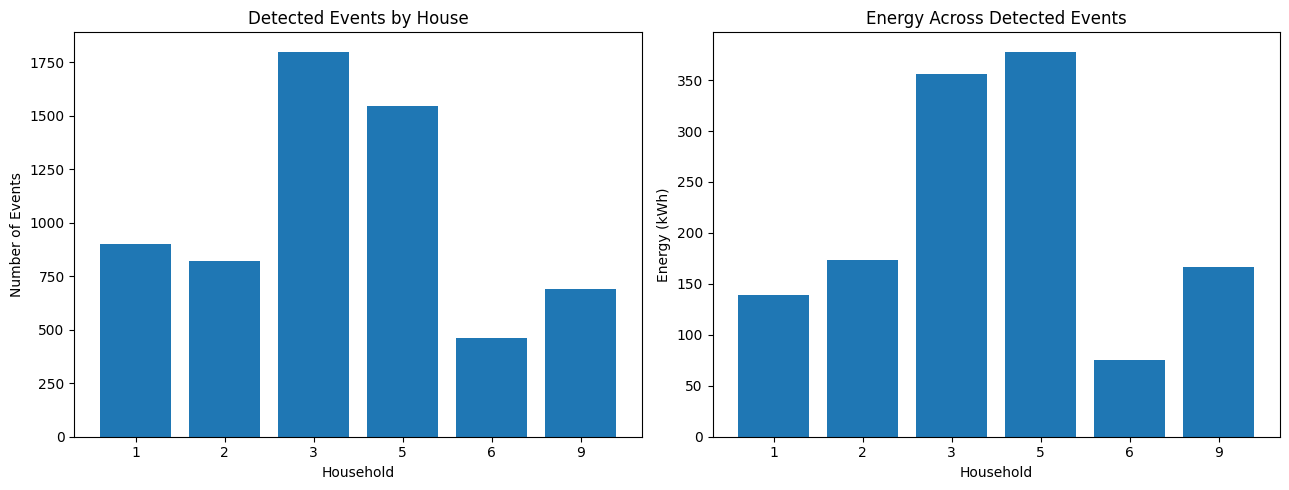

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    event_summary["House"].astype(str),
    event_summary["Detected_events"]
)
axes[0].set_title("Detected Events by House")
axes[0].set_xlabel("Household")
axes[0].set_ylabel("Number of Events")

axes[1].bar(
    event_summary["House"].astype(str),
    event_summary["Total_energy_kWh"]
)
axes[1].set_title("Energy Across Detected Events")
axes[1].set_xlabel("Household")
axes[1].set_ylabel("Energy (kWh)")

plt.tight_layout()
plt.show()


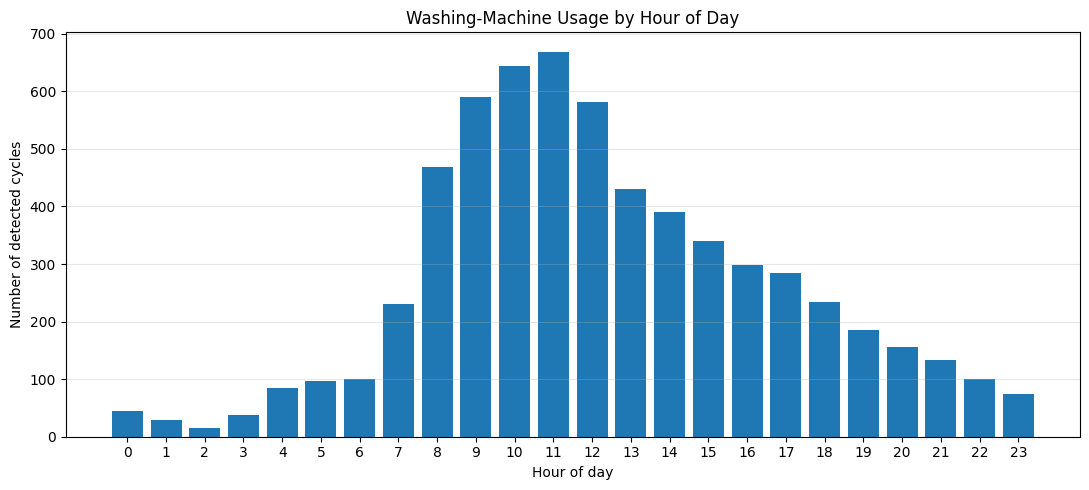

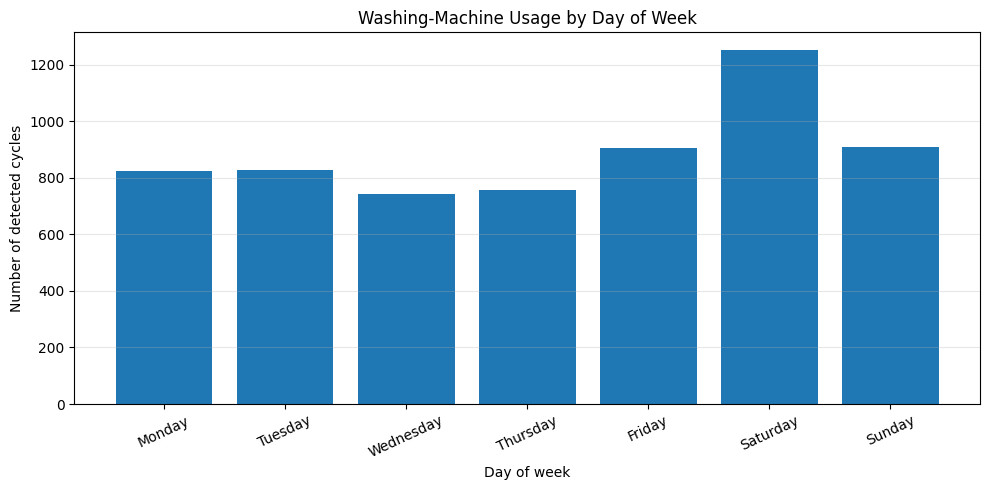

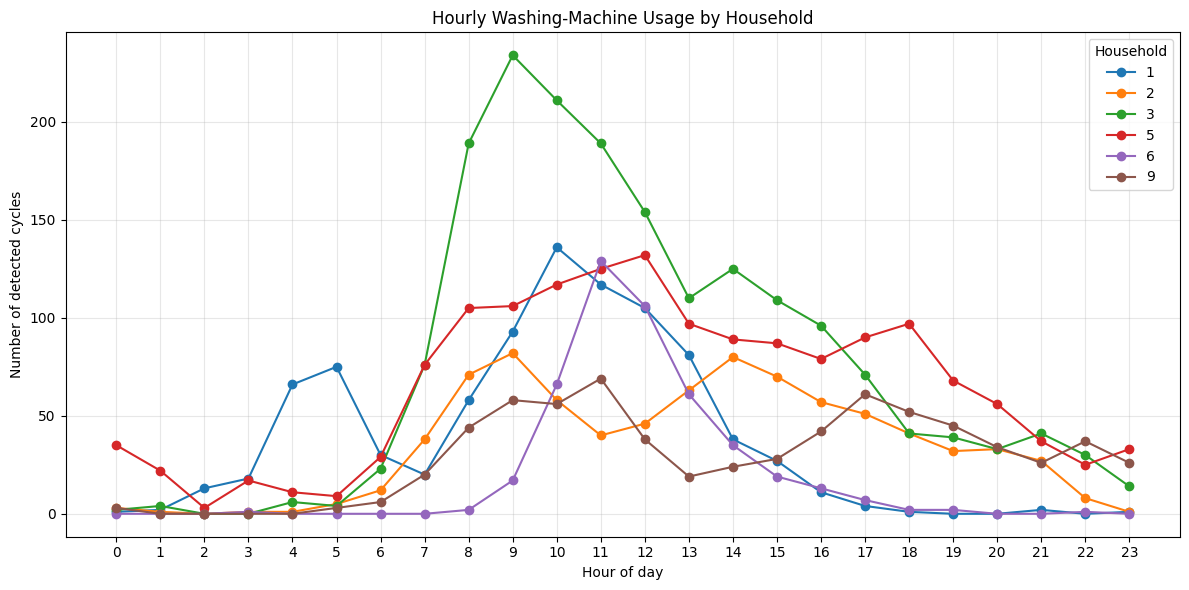

Hourly usage, weekday usage and household comparison completed.
Outputs saved to: C:\Users\jtush\OneDrive\Desktop\Flock_Energy\outputs

Hourly summary:
Hour
0      44
1      29
2      16
3      37
4      84
5      96
6     100
7     230
8     469
9     590
10    644
11    669
12    581
13    431
14    391
15    340
16    298
17    284
18    234
19    186
20    156
21    133
22    101
23     75
dtype: int64

Weekday summary:
Weekday
Monday        825
Tuesday       828
Wednesday     742
Thursday      756
Friday        905
Saturday     1252
Sunday        910
dtype: int64


In [22]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Use the existing detected-cycle tables
# cycle_tables keys: '1', '2', '3', '5', '6', '9'

all_cycles = []

for house, df in cycle_tables.items():
    if df.empty or "Start" not in df.columns:
        continue

    temp = df.copy()
    temp["Start"] = pd.to_datetime(temp["Start"], errors="coerce")
    temp = temp.dropna(subset=["Start"])

    temp["House"] = int(house)
    temp["Hour"] = temp["Start"].dt.hour
    temp["Weekday"] = temp["Start"].dt.dayofweek
    all_cycles.append(temp)

if not all_cycles:
    raise ValueError("No valid detected cycles found in cycle_tables.")

cycles_all = pd.concat(all_cycles, ignore_index=True)

# Save outputs in your existing project output folder
out_dir = Path(OUTPUT_DIR) if "OUTPUT_DIR" in globals() else Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Hour-of-day usage pattern
# --------------------------------------------------
hourly = (
    cycles_all.groupby("Hour")
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(11, 5))
plt.bar(hourly.index, hourly.values)
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Number of detected cycles")
plt.title("Washing-Machine Usage by Hour of Day")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "washing_machine_hourly_usage.png", dpi=200)
plt.show()

# --------------------------------------------------
# 2. Day-of-week usage pattern
# --------------------------------------------------
weekday_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_counts = (
    cycles_all.groupby("Weekday")
    .size()
    .reindex(range(7), fill_value=0)
)

plt.figure(figsize=(10, 5))
plt.bar(weekday_names, weekday_counts.values)
plt.xlabel("Day of week")
plt.ylabel("Number of detected cycles")
plt.title("Washing-Machine Usage by Day of Week")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "washing_machine_weekday_usage.png", dpi=200)
plt.show()

# --------------------------------------------------
# 3. Compare hourly usage across households
# --------------------------------------------------
house_hourly = pd.crosstab(
    cycles_all["Hour"], cycles_all["House"]
).reindex(range(24), fill_value=0)

ax = house_hourly.plot(
    figsize=(12, 6), marker="o", linewidth=1.5
)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of detected cycles")
ax.set_title("Hourly Washing-Machine Usage by Household")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend(title="Household")
plt.tight_layout()
plt.savefig(out_dir / "washing_machine_hourly_by_house.png", dpi=200)
plt.show()

# Export tables
hourly.rename("Detected_cycles").to_csv(
    out_dir / "hourly_usage_summary.csv"
)
weekday_counts.rename("Detected_cycles").to_csv(
    out_dir / "weekday_usage_summary.csv"
)
house_hourly.to_csv(out_dir / "hourly_usage_by_house.csv")

print("Hourly usage, weekday usage and household comparison completed.")
print(f"Outputs saved to: {out_dir.resolve()}")
print("\nHourly summary:")
print(hourly)
print("\nWeekday summary:")
print(weekday_counts.rename(index=dict(enumerate(weekday_names))))


In [23]:

print("Type:", type(info["one_min"]))
print("Shape:", info["one_min"].shape)
print("Columns:")
print(info["one_min"].columns.tolist())
print("\nFirst five rows:")
display(info["one_min"].head())


Type: <class 'pandas.core.frame.DataFrame'>
Shape: (818007, 2)
Columns:
['Appliance3', 'Aggregate']

First five rows:


,Appliance3,Aggregate
Time,,
2013-12-17 17:26:00,0.0,198.000000
2013-12-17 17:27:00,0.0,198.666667
2013-12-17 17:28:00,0.0,197.428571
2013-12-17 17:29:00,0.0,197.800000
2013-12-17 17:30:00,0.0,197.700000


,House,Median_duration_min,Median_peak_W,Median_energy_Wh
0,1,12.0,603.20,58.95
1,2,9.0,266.75,21.69
2,3,12.0,401.67,33.02
3,5,9.0,467.00,83.91
4,6,12.0,278.11,36.70
5,9,15.0,365.00,45.66


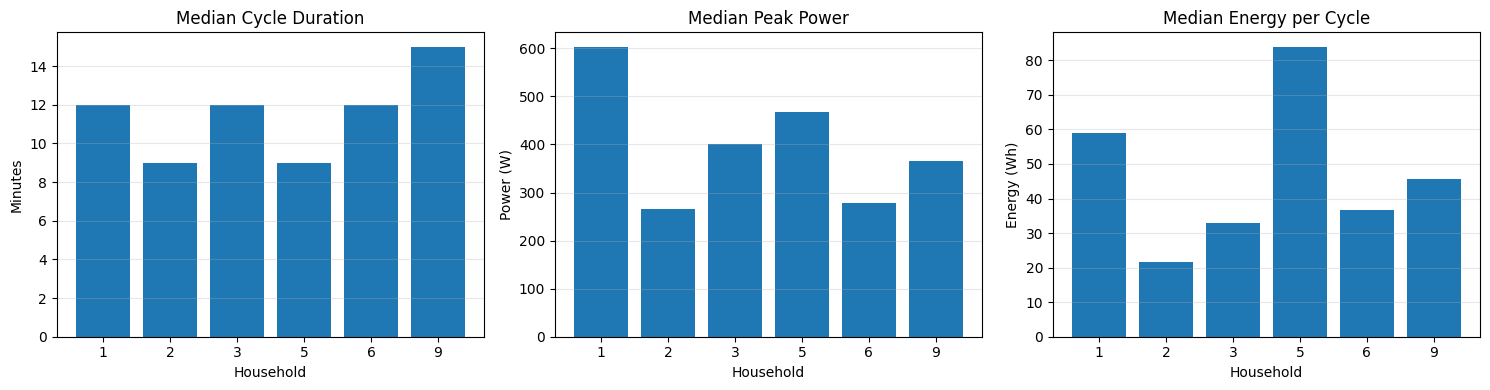

In [24]:

import pandas as pd
import matplotlib.pyplot as plt

# Summarise detected washing-machine cycles by household
comparison_rows = []

for house, df in cycle_tables.items():
    if df.empty:
        continue

    comparison_rows.append({
        "House": int(house),
        "Median_duration_min": df["Duration_min"].median(),
        "Median_peak_W": df["Peak_power_W"].median(),
        "Median_energy_Wh": df["Energy_Wh"].median()
    })

cycle_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("House")
    .reset_index(drop=True)
)

display(cycle_comparison.round(2))

# Compare three characteristics with separate y-axes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("Median_duration_min", "Median Cycle Duration", "Minutes"),
    ("Median_peak_W", "Median Peak Power", "Power (W)"),
    ("Median_energy_Wh", "Median Energy per Cycle", "Energy (Wh)")
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    ax.bar(cycle_comparison["House"].astype(str),
           cycle_comparison[column])
    ax.set_title(title)
    ax.set_xlabel("Household")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "cycle_characteristics_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


In [25]:

# Find the dataframe containing both aggregate and appliance readings
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = set(map(str, obj.columns))
        if "Aggregate" in cols and any(c.startswith("Appliance") for c in cols):
            print(
                f"Variable: {name} | Shape: {obj.shape} | "
                f"Columns: {list(obj.columns)}"
            )


Variable: sample | Shape: (10081, 2) | Columns: ['Appliance3', 'Aggregate']
Variable: one_min | Shape: (818007, 2) | Columns: ['Appliance3', 'Aggregate']
Variable: data | Shape: (818007, 2) | Columns: ['Appliance3', 'Aggregate']
Variable: df1 | Shape: (920091, 2) | Columns: ['Appliance5', 'Aggregate']


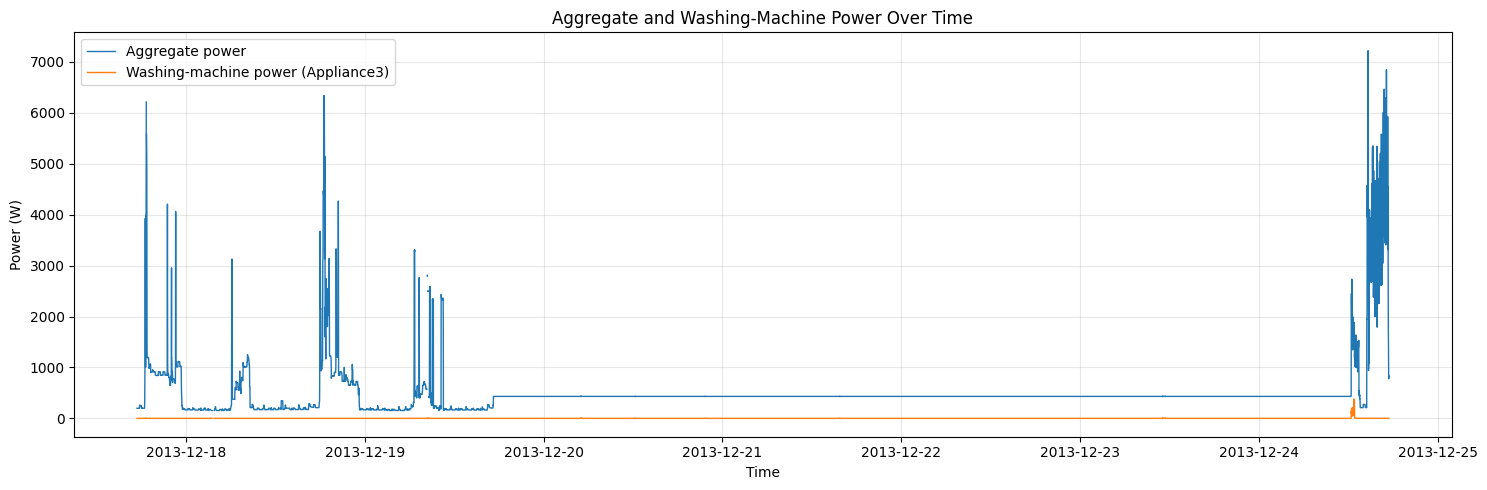

In [26]:

import matplotlib.pyplot as plt
import pandas as pd

# Use the representative sample
plot_df = sample.copy()

# Ensure the index is datetime
plot_df.index = pd.to_datetime(plot_df.index)

# Plot both power channels
fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(
    plot_df.index,
    plot_df["Aggregate"],
    label="Aggregate power",
    linewidth=1
)
ax1.plot(
    plot_df.index,
    plot_df["Appliance3"],
    label="Washing-machine power (Appliance3)",
    linewidth=1
)

ax1.set_title("Aggregate and Washing-Machine Power Over Time")
ax1.set_xlabel("Time")
ax1.set_ylabel("Power (W)")
ax1.legend()
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "aggregate_vs_washing_machine.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


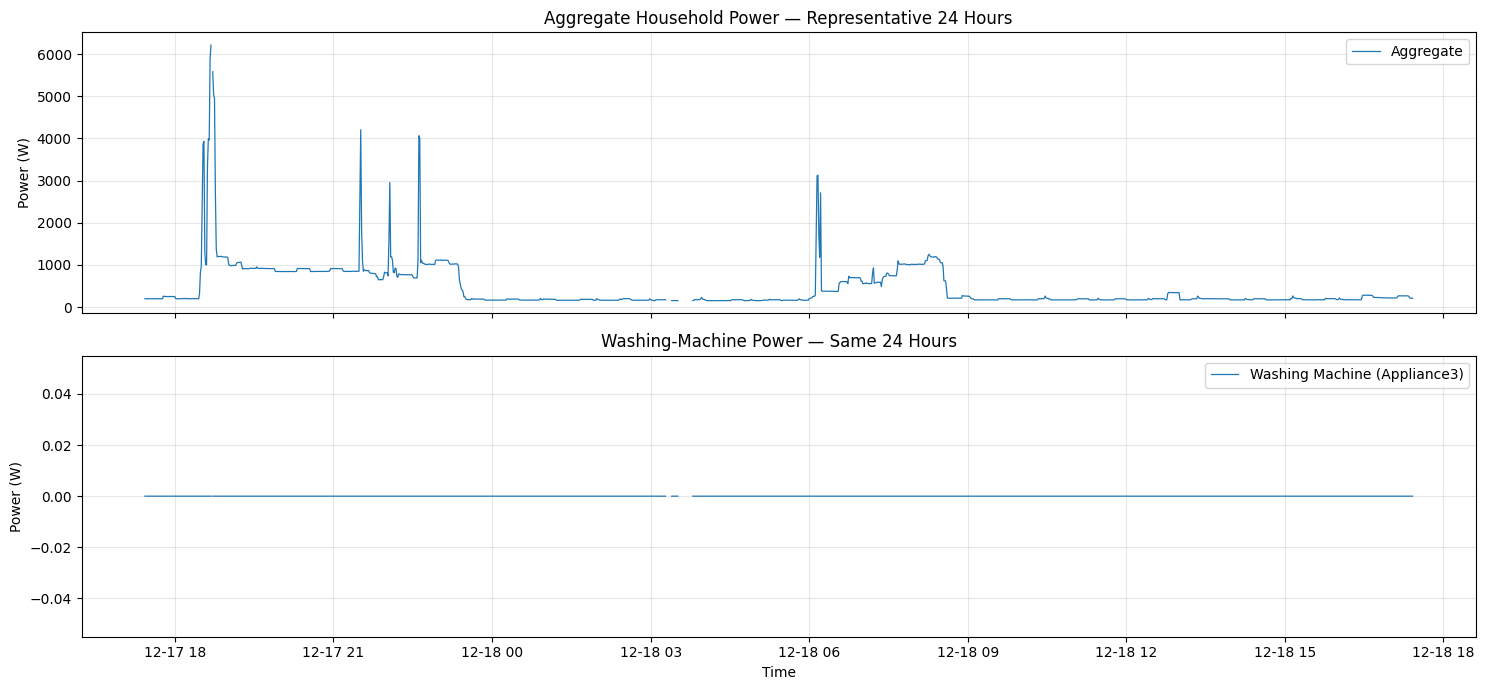

Start: 2013-12-17 17:26:00
End: 2013-12-18 17:25:00
Rows: 1440


In [27]:

import pandas as pd
import matplotlib.pyplot as plt

plot_df = sample.copy()
plot_df.index = pd.to_datetime(plot_df.index)
plot_df = plot_df.sort_index()

# Select the first 24 hours
start_time = plot_df.index.min()
end_time = start_time + pd.Timedelta(hours=24)

day_df = plot_df.loc[
    (plot_df.index >= start_time) &
    (plot_df.index < end_time)
]

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

axes[0].plot(
    day_df.index, day_df["Aggregate"],
    linewidth=0.9, label="Aggregate"
)
axes[0].set_title("Aggregate Household Power — Representative 24 Hours")
axes[0].set_ylabel("Power (W)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    day_df.index, day_df["Appliance3"],
    linewidth=0.9, label="Washing Machine (Appliance3)"
)
axes[1].set_title("Washing-Machine Power — Same 24 Hours")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Power (W)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "representative_24h_aggregate_and_washing_machine.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

print("Start:", day_df.index.min())
print("End:", day_df.index.max())
print("Rows:", len(day_df))


Selected period: 2014-06-15 20:47:00 to 2014-06-16 20:46:00
Positive Appliance3 readings: 1402


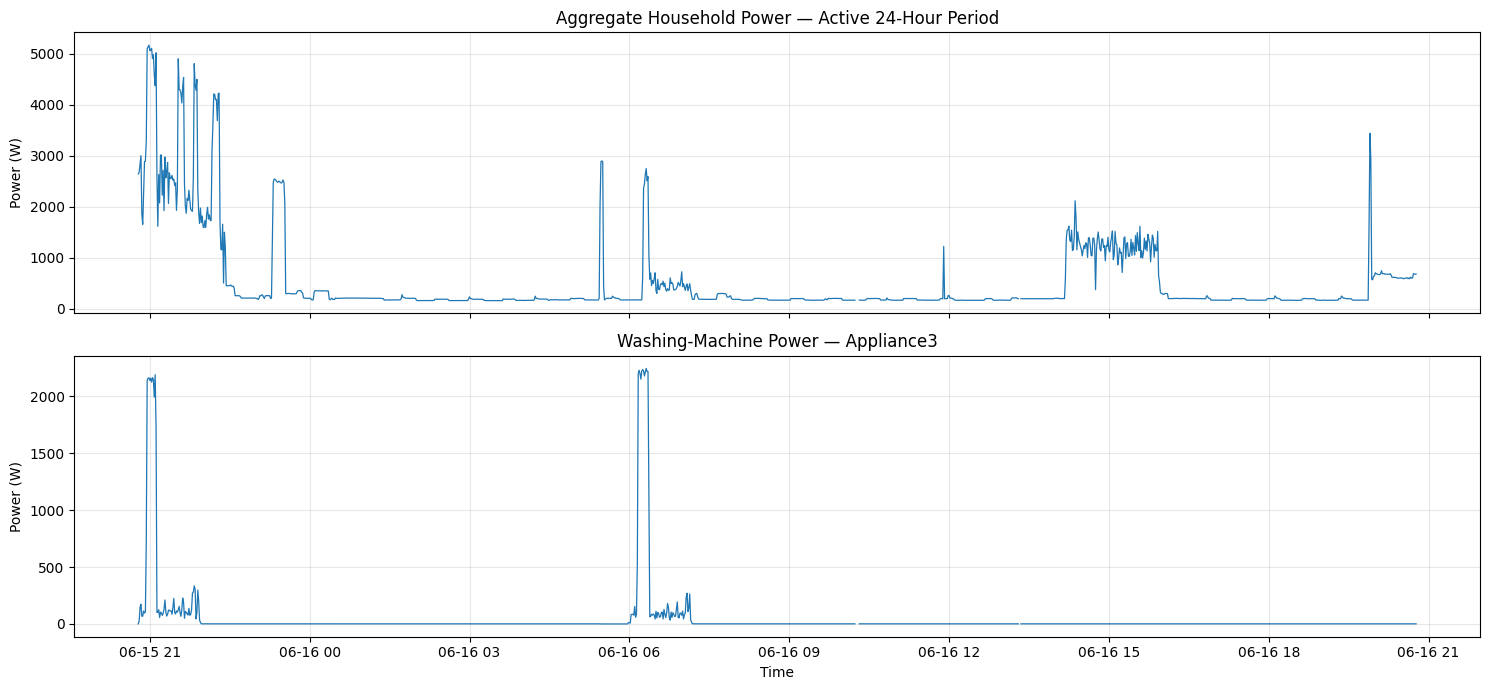

In [28]:

import pandas as pd
import matplotlib.pyplot as plt

# Use the full cleaned one-minute dataframe
plot_df = one_min.copy()
plot_df.index = pd.to_datetime(plot_df.index)
plot_df = plot_df.sort_index()

# Count positive Appliance3 readings in each rolling 24-hour window
active = plot_df["Appliance3"].fillna(0).gt(0).astype(int)

rolling_active = active.rolling(
    window=1440,
    min_periods=1440
).sum()

if rolling_active.dropna().empty or rolling_active.max() == 0:
    print("No active Appliance3 readings found. Check the channel and household mapping.")
else:
    end_time = rolling_active.idxmax()
    start_time = end_time - pd.Timedelta(minutes=1439)

    day_df = plot_df.loc[
        (plot_df.index >= start_time) &
        (plot_df.index <= end_time)
    ]

    print("Selected period:", start_time, "to", end_time)
    print("Positive Appliance3 readings:", int(active.loc[day_df.index].sum()))

    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

    axes[0].plot(day_df.index, day_df["Aggregate"], linewidth=0.9)
    axes[0].set_title("Aggregate Household Power — Active 24-Hour Period")
    axes[0].set_ylabel("Power (W)")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(day_df.index, day_df["Appliance3"], linewidth=0.9)
    axes[1].set_title("Washing-Machine Power — Appliance3")
    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Power (W)")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "active_24h_aggregate_washing_machine.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()


In [29]:
# Inspect available detected-cycle tables
for house, df in cycle_tables.items():
    print(f"\nHouse {house}")
    print("Detected cycles:", len(df))
    print(df.head(3).to_string(index=False))


House 1
Detected cycles: 899
              Start                 End  Duration_min  Peak_power_W  Mean_power_W  Energy_Wh
2013-10-23 06:00:00 2013-10-23 06:09:00            10   2325.700000   1275.422222 212.570370
2013-10-23 06:13:00 2013-10-23 06:32:00            20    349.300000    121.320657  40.440219
2013-10-23 06:40:00 2013-10-23 06:49:00            10   2368.727273   1338.319091 223.053182

House 2
Detected cycles: 821
              Start                 End  Duration_min  Peak_power_W  Mean_power_W   Energy_Wh
2013-09-20 07:57:00 2013-09-20 08:34:00            38   2095.600000   1763.546119 1116.912542
2013-09-20 08:45:00 2013-09-20 08:52:00             8    238.555556    124.162847   16.555046
2013-09-20 09:20:00 2013-09-20 09:24:00             5    306.500000    235.020000   19.585000

House 3
Detected cycles: 1801
              Start                 End  Duration_min  Peak_power_W  Mean_power_W  Energy_Wh
2013-09-26 08:32:00 2013-09-26 08:44:00            13        1875.9 

In [32]:

import pandas as pd
import matplotlib.pyplot as plt

# Select the first detected cycle for House 1
house = 1
events = cycle_tables[house]
event = events.iloc[0]

start = pd.to_datetime(event["Start"])
end = pd.to_datetime(event["End"])

# Check which data variables contain the correct time period
print("Cycle:", start, "to", end)
print("Available data variables:")
print("one_min:", one_min.index.min(), "to", one_min.index.max())
print("data:", data.index.min(), "to", data.index.max())


Cycle: 2013-10-23 06:00:00 to 2013-10-23 06:09:00
Available data variables:
one_min: 2013-12-17 17:26:00 to 2015-07-08 18:52:00
data: 2013-12-17 17:26:00 to 2015-07-08 18:52:00


In [33]:
from pathlib import Path

print("Cleaned data directory:", CLEANED_DIR)

for file in Path(CLEANED_DIR).glob("*"):
    print(file.name)

Cleaned data directory: c:\Users\jtush\OneDrive\Desktop\Flock_Energy\data\cleaned
CLEAN_House1.csv
CLEAN_House10.csv
CLEAN_House11.csv
CLEAN_House12.csv
CLEAN_House13.csv
CLEAN_House15.csv
CLEAN_House16.csv
CLEAN_House17.csv
CLEAN_House18.csv
CLEAN_House19.csv
CLEAN_House2.csv
CLEAN_House20.csv
CLEAN_House21.csv
CLEAN_House3.csv
CLEAN_House4.csv
CLEAN_House5.csv
CLEAN_House6.csv
CLEAN_House7.csv
CLEAN_House8.csv
CLEAN_House9.csv


In [34]:
from pathlib import Path

for file in Path(CLEANED_DIR).glob("*.csv"):
    print(file.name)

CLEAN_House1.csv
CLEAN_House10.csv
CLEAN_House11.csv
CLEAN_House12.csv
CLEAN_House13.csv
CLEAN_House15.csv
CLEAN_House16.csv
CLEAN_House17.csv
CLEAN_House18.csv
CLEAN_House19.csv
CLEAN_House2.csv
CLEAN_House20.csv
CLEAN_House21.csv
CLEAN_House3.csv
CLEAN_House4.csv
CLEAN_House5.csv
CLEAN_House6.csv
CLEAN_House7.csv
CLEAN_House8.csv
CLEAN_House9.csv


In [35]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the correct household file
file_path = Path(CLEANED_DIR) / "CLEAN_House1.csv"
house1 = pd.read_csv(file_path, index_col=0, parse_dates=True)

print("Shape:", house1.shape)
print("Columns:", house1.columns.tolist())
print("Date range:", house1.index.min(), "to", house1.index.max())
print(house1.head())

Shape: (6960008, 12)
Columns: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
Date range: 2013-10-09 13:06:17 to 2015-07-10 11:56:32
                           Unix  Aggregate  Appliance1  Appliance2  \
Time                                                                 
2013-10-09 13:06:17  1381323977        523          74           0   
2013-10-09 13:06:31  1381323991        526          75           0   
2013-10-09 13:06:46  1381324006        540          74           0   
2013-10-09 13:07:01  1381324021        532          74           0   
2013-10-09 13:07:15  1381324035        540          74           0   

                     Appliance3  Appliance4  Appliance5  Appliance6  \
Time                                                                  
2013-10-09 13:06:17          69           0           0           0   
2013-10-09 13:06:31          69           0          

Columns: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']


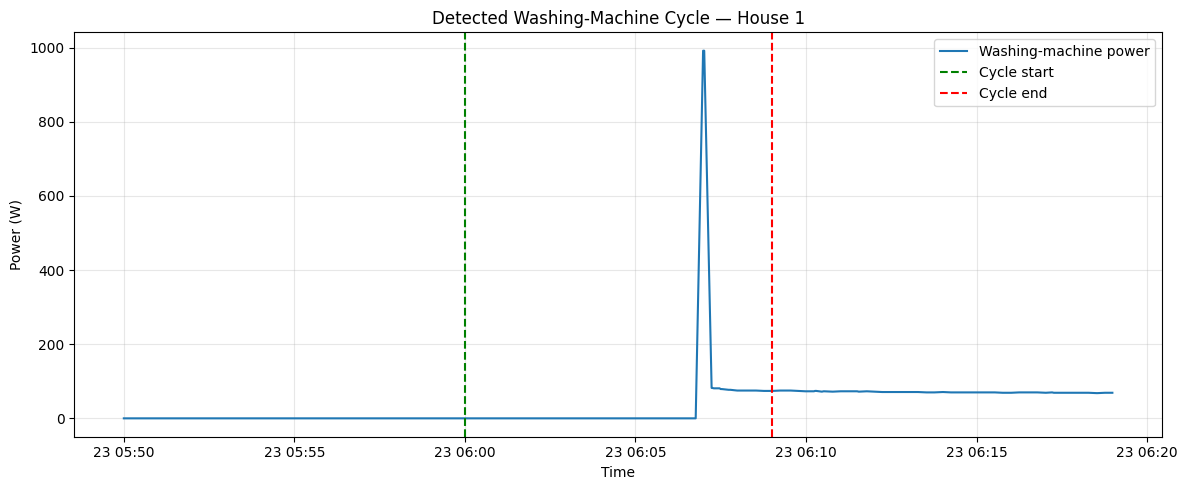

Duration: 10 minutes
Peak power: 2325.70 W
Energy: 212.57 Wh


In [36]:
# Select the first detected cycle
event = cycle_tables[1].iloc[0]
start = pd.to_datetime(event["Start"])
end = pd.to_datetime(event["End"])

# Check available columns
print("Columns:", house1.columns.tolist())

# Find the washing-machine channel
wm_col = next(
    (c for c in house1.columns if "Appliance3" in c),
    None
)

if wm_col is None:
    raise ValueError("Appliance3 column not found. Check the printed columns.")

# Ensure chronological datetime index
house1.index = pd.to_datetime(house1.index)
house1 = house1.sort_index()

# Extract a 10-minute window before and after the event
window = house1.loc[
    start - pd.Timedelta(minutes=10):
    end + pd.Timedelta(minutes=10)
]

if window.empty:
    print("No readings found around this cycle. Check the file's date range.")
else:
    plt.figure(figsize=(12, 5))
    plt.plot(window.index, window[wm_col], label="Washing-machine power")
    plt.axvline(start, color="green", linestyle="--", label="Cycle start")
    plt.axvline(end, color="red", linestyle="--", label="Cycle end")
    plt.title("Detected Washing-Machine Cycle — House 1")
    plt.xlabel("Time")
    plt.ylabel("Power (W)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Duration: {event['Duration_min']} minutes")
    print(f"Peak power: {event['Peak_power_W']:.2f} W")
    print(f"Energy: {event['Energy_Wh']:.2f} Wh")

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Use the cleaned House 1 file
file_path = CLEANED_DIR / "CLEAN_House1.csv"
df = pd.read_csv(file_path)

print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
print(df.head())

Columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
Shape: (6960008, 13)
                  Time        Unix  Aggregate  Appliance1  Appliance2  \
0  2013-10-09 13:06:17  1381323977        523          74           0   
1  2013-10-09 13:06:31  1381323991        526          75           0   
2  2013-10-09 13:06:46  1381324006        540          74           0   
3  2013-10-09 13:07:01  1381324021        532          74           0   
4  2013-10-09 13:07:15  1381324035        540          74           0   

   Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  \
0          69           0           0           0           0           0   
1          69           0           0           0           0           0   
2          68           0           0           0           0           0   
3          68           0           0           0        

House: 1
Channel: Appliance3
Readings in event: 87
First reading: 2013-10-23 06:00:01
Last reading: 2013-10-23 06:08:59
Duration: 10.0 minutes
Peak power: 992.00 W
Approximate energy: 6.37 Wh


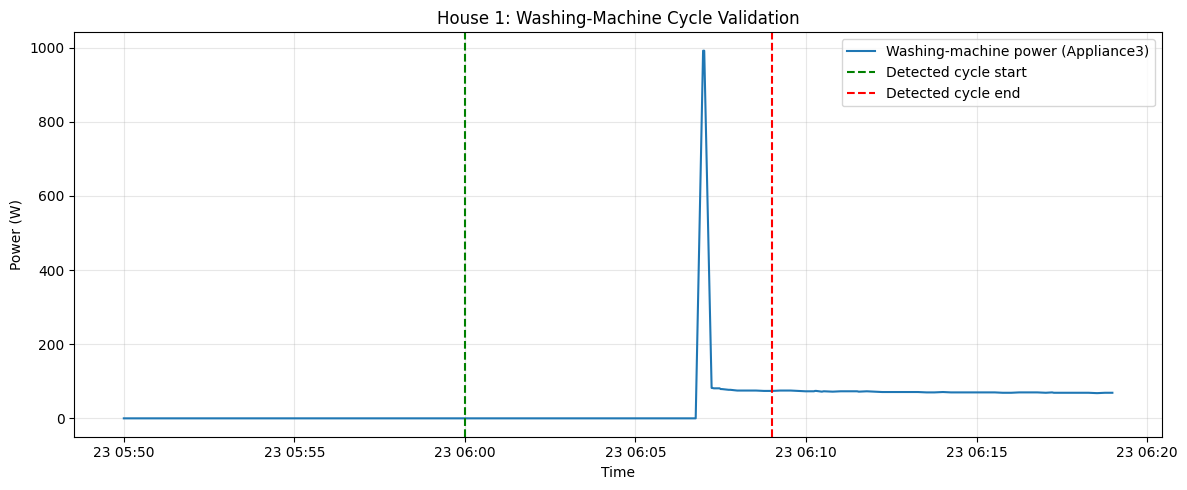

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned House 1 data
df = pd.read_csv(CLEANED_DIR / "CLEAN_House1.csv")

# Prepare timestamps and numeric readings
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
df["Appliance3"] = pd.to_numeric(df["Appliance3"], errors="coerce")

df = (
    df.dropna(subset=["Time"])
      .sort_values("Time")
      .drop_duplicates(subset=["Time"], keep="last")
      .set_index("Time")
)

# Selected detected event
start = pd.Timestamp("2013-10-23 06:00:00")
end   = pd.Timestamp("2013-10-23 06:09:00")

# Extract event and surrounding context
window = df.loc[
    start - pd.Timedelta(minutes=10):
    end + pd.Timedelta(minutes=10),
    "Appliance3"
]

event = df.loc[start:end, "Appliance3"].dropna()

if event.empty:
    print("No readings found inside the selected event.")
    print("Available timestamps around the event:")
    print(window)
else:
    # Recalculate metrics using the actual readings
    duration_min = (
        event.index.max() - event.index.min()
    ).total_seconds() / 60 + 1

    peak_power = event.max()

    # For irregularly sampled readings, integrate over elapsed time.
    # This assumes each reading represents power in watts.
    energy_wh = (
        event.iloc[:-1].to_numpy()
        * np.diff(event.index.asi8) / 3.6e12
    ).sum()

    print("House: 1")
    print("Channel: Appliance3")
    print("Readings in event:", len(event))
    print("First reading:", event.index.min())
    print("Last reading:", event.index.max())
    print(f"Duration: {duration_min:.1f} minutes")
    print(f"Peak power: {peak_power:.2f} W")
    print(f"Approximate energy: {energy_wh:.2f} Wh")

    # Plot the trace with actual event boundaries
    plt.figure(figsize=(12, 5))
    plt.plot(window.index, window.values,
             label="Washing-machine power (Appliance3)")
    plt.axvline(start, color="green", linestyle="--",
                label="Detected cycle start")
    plt.axvline(end, color="red", linestyle="--",
                label="Detected cycle end")
    plt.title("House 1: Washing-Machine Cycle Validation")
    plt.xlabel("Time")
    plt.ylabel("Power (W)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Selected day: 2014-11-28
Rows: 12852
Positive washing-machine readings: 8096


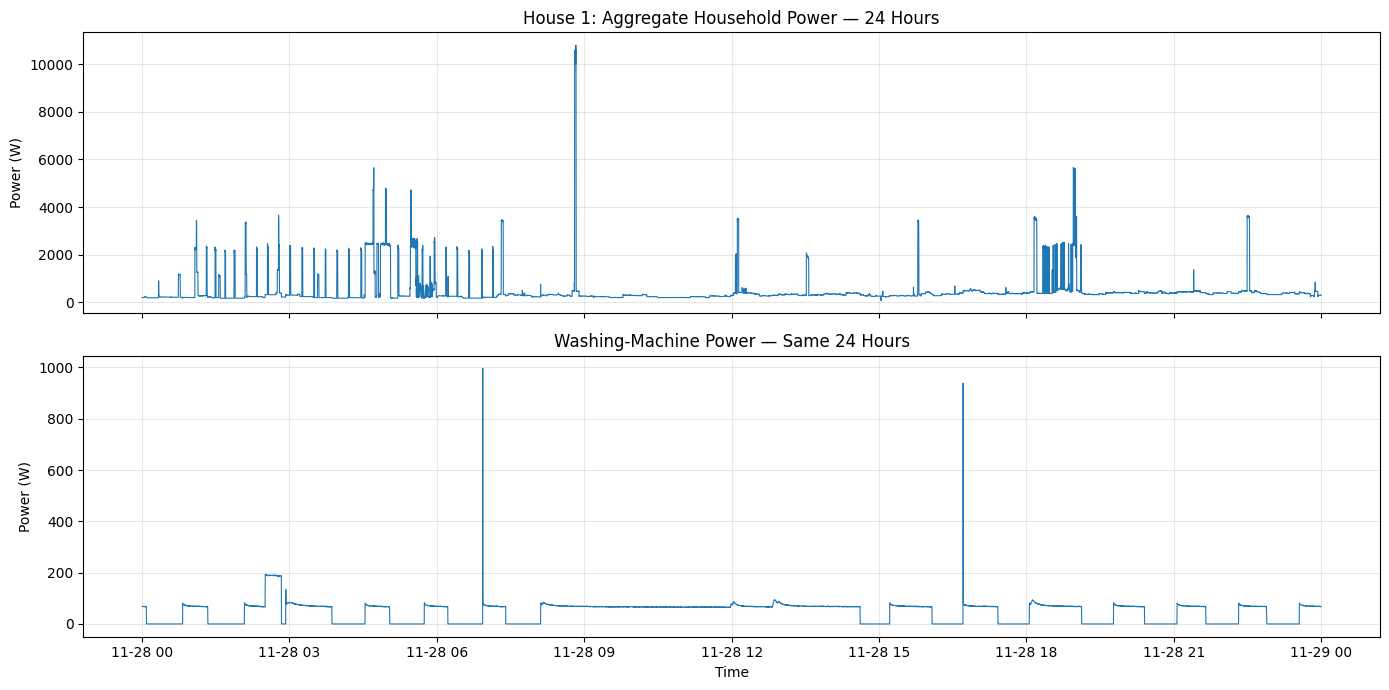

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the cleaned House 1 data
df = pd.read_csv(CLEANED_DIR / "CLEAN_House1.csv")
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

for col in ["Aggregate", "Appliance3"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Time"])
      .sort_values("Time")
      .drop_duplicates(subset=["Time"], keep="last")
      .set_index("Time")
)

# Find a day with the greatest number of positive
# washing-machine readings
daily_activity = (
    df["Appliance3"].gt(0)
      .resample("D")
      .sum()
)

best_day = daily_activity.idxmax()
next_day = best_day + pd.Timedelta(days=1)

day = df.loc[best_day:next_day].iloc[:-1]

print("Selected day:", best_day.date())
print("Rows:", len(day))
print("Positive washing-machine readings:",
      int(day["Appliance3"].gt(0).sum()))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(day.index, day["Aggregate"], linewidth=0.8)
axes[0].set_title("House 1: Aggregate Household Power — 24 Hours")
axes[0].set_ylabel("Power (W)")
axes[0].grid(alpha=0.3)

axes[1].plot(day.index, day["Appliance3"], linewidth=0.8)
axes[1].set_title("Washing-Machine Power — Same 24 Hours")
axes[1].set_ylabel("Power (W)")
axes[1].set_xlabel("Time")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Start: 2014-11-28 00:00:00
End: 2014-11-28 23:59:00
Rows: 1440
Median sampling interval: 0 days 00:01:00


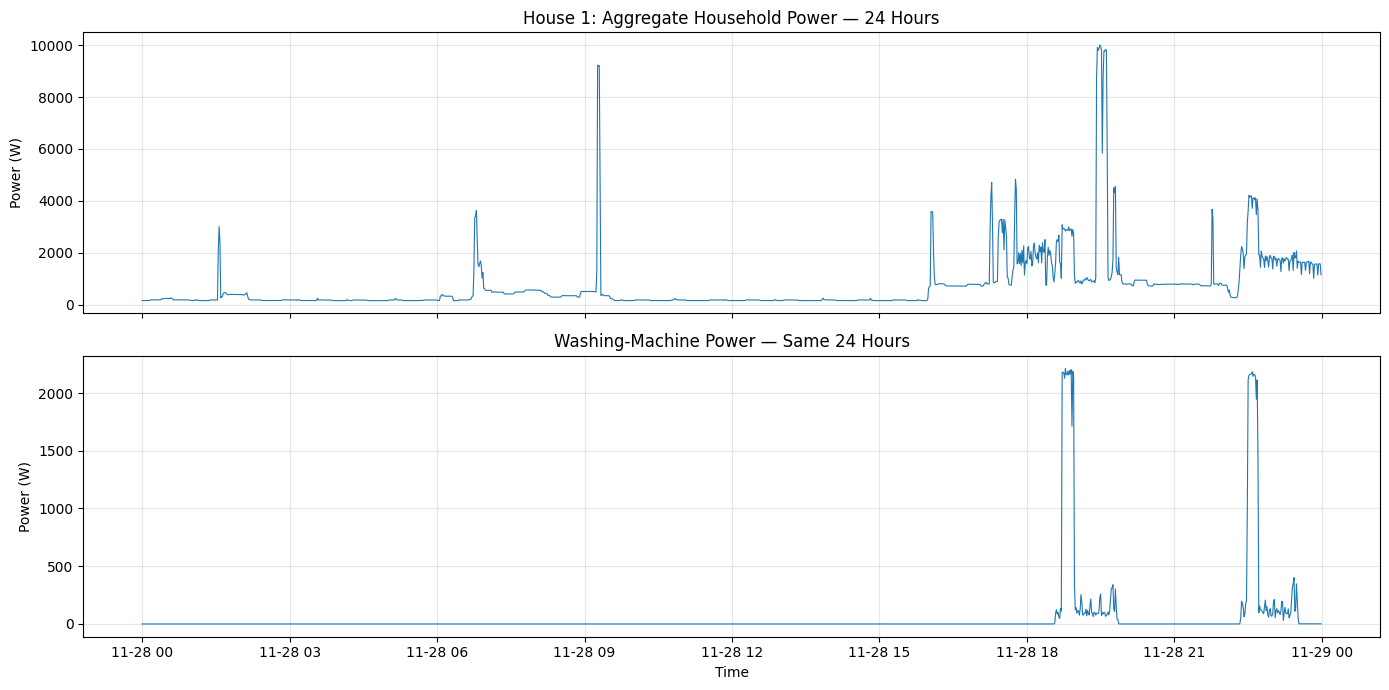

In [40]:
import matplotlib.pyplot as plt

# Select a representative 24-hour period
day = "2014-11-28"

daily = one_min.loc[day, ["Aggregate", "Appliance3"]].copy()
daily = daily.sort_index()

print("Start:", daily.index.min())
print("End:", daily.index.max())
print("Rows:", len(daily))
print("Median sampling interval:",
      daily.index.to_series().diff().median())

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(daily.index, daily["Aggregate"], linewidth=0.8)
ax[0].set_title("House 1: Aggregate Household Power — 24 Hours")
ax[0].set_ylabel("Power (W)")
ax[0].grid(True, alpha=0.3)

ax[1].plot(daily.index, daily["Appliance3"], linewidth=0.8)
ax[1].set_title("Washing-Machine Power — Same 24 Hours")
ax[1].set_ylabel("Power (W)")
ax[1].set_xlabel("Time")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [50]:
import pandas as pd
from pathlib import Path

base = Path.cwd().parent
files = list(base.rglob("CLEAN_House*.csv"))

house_data = {}

for file in files:
    house = int(file.stem.replace("CLEAN_House", ""))

    df = pd.read_csv(file)

    # Identify and parse the timestamp column
    time_col = next(
        (c for c in df.columns
         if c.strip().lower() in ["time", "datetime", "timestamp"]),
        None
    )

    if time_col is not None:
        df[time_col] = pd.to_datetime(df[time_col], errors="coerce")
        df = df.dropna(subset=[time_col]).set_index(time_col)

    df.index = pd.to_datetime(df.index, errors="coerce")
    df = df.loc[~df.index.isna()].sort_index()

    house_data[house] = df

print("Loaded households:", sorted(house_data.keys()))
print("\nHouse 1 columns:", house_data[1].columns.tolist())
print("\nHouse 1 sample:")
display(house_data[1].head())

Loaded households: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21]

House 1 columns: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']

House 1 sample:


,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
Time,,,,,,,,,,,,
2013-10-09 13:06:17,1381323977,523,74,0,69,0,0,0,0,0,1,0
2013-10-09 13:06:31,1381323991,526,75,0,69,0,0,0,0,0,1,0
2013-10-09 13:06:46,1381324006,540,74,0,68,0,0,0,0,0,1,0
2013-10-09 13:07:01,1381324021,532,74,0,68,0,0,0,0,0,1,0
2013-10-09 13:07:15,1381324035,540,74,0,69,0,0,0,0,0,1,0


In [51]:
for house in [1, 2, 3, 5, 6, 9]:
    if house in house_data:
        print(
            f"House {house}:",
            house_data[house].columns.tolist()
        )

House 1: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
House 2: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
House 3: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
House 5: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
House 6: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
House 9: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues'

In [52]:
import pandas as pd

houses = [1, 2, 3, 5, 6, 9]
quality_rows = []

# Cycle tables generated earlier
print("Cycle-table keys:", list(cycle_tables.keys()))

for house in houses:
    df = house_data[house].sort_index()
    s = df["Appliance3"]

    # Sampling intervals
    gaps = df.index.to_series().diff()
    valid_gaps = gaps.dropna()

    # Approximate one-minute sampling checks
    long_gaps = valid_gaps > pd.Timedelta(minutes=1)

    # Cycle count, handling integer or string keys
    events = cycle_tables.get(
        house, cycle_tables.get(str(house), pd.DataFrame())
    )

    quality_rows.append({
        "House": house,
        "Start": df.index.min(),
        "End": df.index.max(),
        "Readings": len(df),
        "Missing_values": int(s.isna().sum()),
        "Gaps_over_1min": int(long_gaps.sum()),
        "Longest_gap_min": (
            valid_gaps.max().total_seconds() / 60
            if len(valid_gaps) else 0
        ),
        "Zero_readings_pct": round((s == 0).mean() * 100, 2),
        "Positive_readings_pct": round((s > 0).mean() * 100, 2),
        "Detected_cycles": len(events)
    })

quality = pd.DataFrame(quality_rows)
display(quality)

Cycle-table keys: [1, 2, 3, 5, 6, 9]


,House,Start,End,Readings,Missing_values,Gaps_over_1min,Longest_gap_min,Zero_readings_pct,Positive_readings_pct,Detected_cycles
0,1,2013-10-09 13:06:17,2015-07-10 11:56:32,6960008,0,3440,59906.883333,59.77,40.23,899
1,2,2013-09-17 22:08:11,2015-05-28 08:05:43,5733526,0,2305,89315.050000,92.00,8.00,821
2,3,2013-09-25 19:21:09,2015-06-02 10:55:42,6994594,0,3407,59906.933333,59.48,40.52,1801
3,5,2013-09-26 09:56:09,2015-07-06 17:48:55,7430755,0,3973,12454.150000,51.76,48.24,1545
4,6,2013-11-28 12:15:35,2015-06-28 22:14:45,6241971,0,5030,48316.650000,98.26,1.74,461
5,9,2013-12-17 17:26:20,2015-07-08 18:52:50,6169525,0,2764,59906.883333,90.70,9.30,691


In [53]:
import pandas as pd
import numpy as np

houses = [1, 2, 3, 5, 6, 9]
minute_data = {}

for house in houses:
    df = house_data[house].copy()

    # Ensure a datetime index
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    # Convert irregular readings to one-minute average power
    df = df[~df.index.duplicated(keep="first")]

    minute_df = df.resample("1min").mean()

    # Fill only short gaps (up to 2 consecutive minutes)
    minute_df = minute_df.interpolate(
        method="time", limit=2, limit_area="inside"
    )

    minute_data[house] = minute_df

print("One-minute data prepared.")
for house, df in minute_data.items():
    print(
        f"House {house}: {len(df)} minutes | "
        f"{df.index.min()} to {df.index.max()}"
    )

One-minute data prepared.
House 1: 920091 minutes | 2013-10-09 13:06:00 to 2015-07-10 11:56:00
House 2: 889078 minutes | 2013-09-17 22:08:00 to 2015-05-28 08:05:00
House 3: 885095 minutes | 2013-09-25 19:21:00 to 2015-06-02 10:55:00
House 5: 933593 minutes | 2013-09-26 09:56:00 to 2015-07-06 17:48:00
House 6: 831480 minutes | 2013-11-28 12:15:00 to 2015-06-28 22:14:00
House 9: 818007 minutes | 2013-12-17 17:26:00 to 2015-07-08 18:52:00


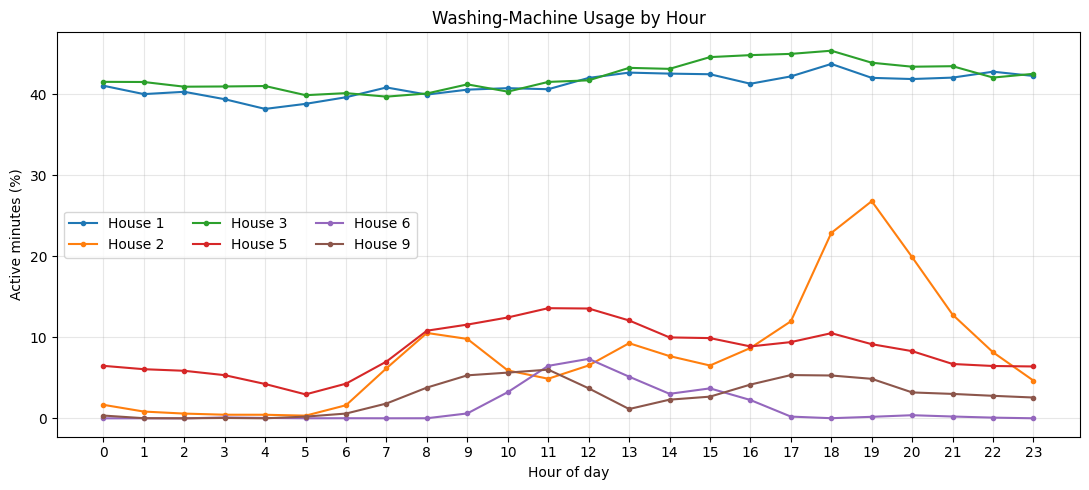

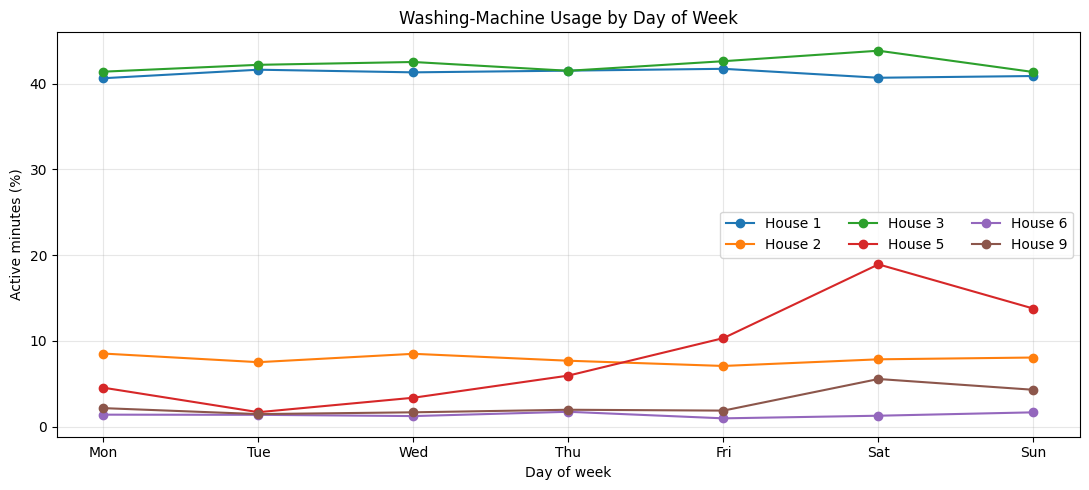

In [54]:
import matplotlib.pyplot as plt

hourly_usage = {}
weekday_usage = {}

for house, df in minute_data.items():
    s = df["Appliance3"].dropna()

    # Active means washing-machine power >= 10 W
    active = s >= 10

    hourly_usage[house] = active.groupby(
        active.index.hour
    ).mean() * 100

    weekday_usage[house] = active.groupby(
        active.index.dayofweek
    ).mean() * 100

# Hour-of-day comparison
plt.figure(figsize=(11, 5))

for house, values in hourly_usage.items():
    plt.plot(values.index, values.values, marker="o",
             markersize=3, label=f"House {house}")

plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Active minutes (%)")
plt.title("Washing-Machine Usage by Hour")
plt.legend(ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Day-of-week comparison: Monday=0, Sunday=6
plt.figure(figsize=(11, 5))

for house, values in weekday_usage.items():
    plt.plot(values.index, values.values, marker="o",
             label=f"House {house}")

plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu",
                      "Fri", "Sat", "Sun"])
plt.xlabel("Day of week")
plt.ylabel("Active minutes (%)")
plt.title("Washing-Machine Usage by Day of Week")
plt.legend(ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,House,Detected_cycles,Median_duration_min,Median_peak_power_W,Median_energy_Wh
0,1,899,12.0,603.20,58.95
1,2,821,9.0,266.75,21.69
2,3,1801,12.0,401.67,33.02
3,5,1545,9.0,467.00,83.91
4,6,461,12.0,278.11,36.70
5,9,691,15.0,365.00,45.66


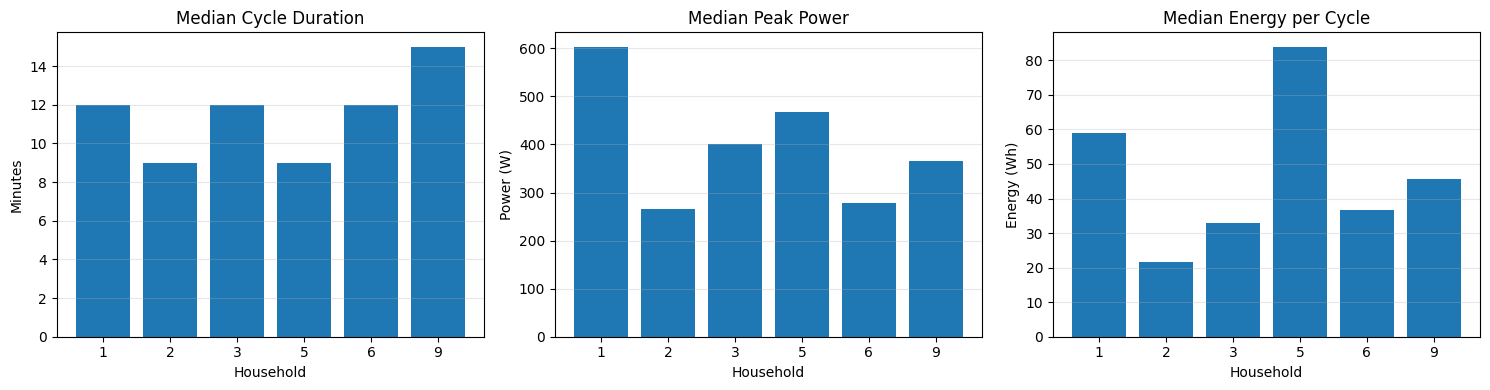

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

# Summarise detected washing-machine cycles across households
comparison = []

for house, events in cycle_tables.items():
    if events.empty:
        continue

    comparison.append({
        "House": house,
        "Detected_cycles": len(events),
        "Median_duration_min": events["Duration_min"].median(),
        "Median_peak_power_W": events["Peak_power_W"].median(),
        "Median_energy_Wh": events["Energy_Wh"].median()
    })

comparison_df = pd.DataFrame(comparison).sort_values("House")

display(comparison_df.round(2))

# Plot comparison of cycle characteristics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("Median_duration_min", "Median Cycle Duration", "Minutes"),
    ("Median_peak_power_W", "Median Peak Power", "Power (W)"),
    ("Median_energy_Wh", "Median Energy per Cycle", "Energy (Wh)")
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    ax.bar(comparison_df["House"].astype(str), comparison_df[column])
    ax.set_title(title)
    ax.set_xlabel("Household")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Cross-House Comparison of Washing-Machine Cycles

Washing-machine usage was analysed across six households (Houses 1, 2, 3, 5, 6, and 9) using cleaned REFIT data at one-minute resolution. Active operating events were detected using the selected threshold and cycle-detection rule.

**Key findings:**

- **Cycle duration:** House 9 had the longest median detected cycle duration at 15 minutes. Houses 1, 3, and 6 had median durations of 12 minutes, while Houses 2 and 5 had shorter median durations of 9 minutes.
- **Peak power:** House 1 had the highest median cycle peak power at 603.20 W, followed by House 5 at 467.00 W. House 2 had the lowest median peak power at 266.75 W.
- **Energy consumption:** House 5 had the highest median energy per detected cycle at 83.91 Wh, followed by House 1 at 58.95 Wh. House 2 had the lowest median at 21.69 Wh.
- **Detected events:** House 3 had the highest number of detected events (1,801), while House 6 had the lowest (461). These counts may reflect differences in monitoring coverage, appliance behaviour, and the cycle-detection method.

### Conclusion

The analysis demonstrates differences in washing-machine usage across households in terms of operating duration, peak power, energy per detected event, and time-of-day patterns. Hourly and weekly profiles show that activity varies across households, with some exhibiting stronger evening or weekend usage.

The results depend on the selected active-power threshold, minimum event duration, and treatment of gaps between readings. Detected events should therefore be interpreted as algorithmically identified operating events rather than confirmed complete washing cycles. Further validation of event boundaries and data quality would improve confidence in the comparisons.